# [GSE50201](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE50201)

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2020-10-15
> - Modified: 2025-01-17

# 1. Experimental Design

> Distinct roles of Tet1 and Tet2 in mouse embryonic stem cells.
> - Y. Huang,L. Chavez,X. Chang,X. Wang,W.A. Pastor,J. Kang,J.A. Zepeda-Martínez,U.J. Pape,S.E. Jacobsen,B. Peters, & A. Rao,  Distinct roles of the methylcytosine oxidases Tet1 and Tet2 in mouse embryonic stem cells, Proc. Natl. Acad. Sci. U.S.A. 111 (4) 1361-1366, https://doi.org/10.1073/pnas.1322921111 (2014).
> - polyA RNA-seq
> - AB SOLiD System, PE, 50+35
> - mm10

| Sample | Organism | Cell | Strain | Treatment | Replicate |
| - | - | - | - | - | - |
| Control | Mus musculus | mESC | V6.5 | Control | rep1~4 |
| Tet1-KD | Mus musculus | mESC | V6.5 | shTet1 | rep1~4 |
| Tet2-KD | Mus musculus | mESC | V6.5 | shTet2 | rep1~4 |

# 2. Preprocessing

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(limma))
suppressPackageStartupMessages(library(edgeR))
suppressPackageStartupMessages(library(DESeq2))
suppressPackageStartupMessages(library(ggrepel))
suppressPackageStartupMessages(library(pheatmap))
suppressPackageStartupMessages(library(patchwork))
suppressPackageStartupMessages(library(RColorBrewer))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


## 1). Import Data

In [2]:
data_dir <- "~/dataset_1/bulk_omics/rnaseq_Mm_mESC_Tets_GSE50201/02_output"

### a). FeatureCounts

In [3]:
raw_counts <- file.path(data_dir, "04_counts", "featureCounts.tsv") |>
    read.table(header = TRUE, sep = "\t", check.names = FALSE)

colnames(raw_counts) <- colnames(raw_counts) |> 
    sub("^02_output/03_align/(.*?).Aligned.out.bam", "\\1", x = _)

dim(raw_counts)

[1] 55335    20

In [4]:
coldata <- colnames(raw_counts) |> 
    tibble(sample = _) |> 
    filter(str_detect(sample, fixed("mESC"))) |> 
    separate(
        col = sample, into = c("Cell", "Gene", "Group", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(
        sample = sub("^[^_]+_", "", sample), 
        Gene = factor(Gene, levels = c("Tets", "Tet1", "Tet2")), 
        Group = factor(Group, levels = c("Ctrl", "KD")), 
        Replicate = factor(Replicate),
        Genotype = paste0(Gene, Group),
        Genotype = ifelse(Genotype == "TetsCtrl", "Control", Genotype) |>
            factor(levels = c("Control", "Tet1KD", "Tet2KD"))) |> 
    arrange(Genotype, Replicate) |>
    mutate(Batch = case_when(
        Replicate %in% paste0("rep", c(1, 2)) ~ "batch1",
        Replicate %in% paste0("rep", c(3, 4)) ~ "batch2"
        ) |> factor()) |>
    column_to_rownames("sample")

coldata

,Cell,Gene,Group,Replicate,Genotype,Batch
,<chr>,<fct>,<fct>,<fct>,<fct>,<fct>
Tets_Ctrl_rep1,mESC,Tets,Ctrl,rep1,Control,batch1
Tets_Ctrl_rep2,mESC,Tets,Ctrl,rep2,Control,batch1
Tets_Ctrl_rep3,mESC,Tets,Ctrl,rep3,Control,batch2
Tets_Ctrl_rep4,mESC,Tets,Ctrl,rep4,Control,batch2
Tet1_KD_rep1,mESC,Tet1,KD,rep1,Tet1KD,batch1
Tet1_KD_rep2,mESC,Tet1,KD,rep2,Tet1KD,batch1
Tet1_KD_rep3,mESC,Tet1,KD,rep3,Tet1KD,batch2
Tet1_KD_rep4,mESC,Tet1,KD,rep4,Tet1KD,batch2
Tet2_KD_rep1,mESC,Tet2,KD,rep1,Tet2KD,batch1


In [5]:
anno_gene <- raw_counts |> 
    select(
        Geneid, symbol = gene_name, type = gene_type, 
        basepairs = Length) |>
    column_to_rownames(var = "Geneid") |> 
    DataFrame()

In [6]:
raw_counts <- raw_counts |>
    column_to_rownames("Geneid") |>
    select(matches("mESC")) |>
    rename_with(~ sub("^[^_]+_", "", .x)) |>
    select(any_of(rownames(coldata))) |>
    as.matrix()

In [7]:
DESeqDataSetFromMatrix(
    countData = raw_counts, rowData = anno_gene,
    colData = coldata, design = ~ Genotype)

class: DESeqDataSet 
dim: 55335 12 
metadata(1): version
assays(1): counts
rownames(55335): ENSMUSG00000102693.1 ENSMUSG00000064842.1 ...
  ENSMUSG00000064371.1 ENSMUSG00000064372.1
rowData names(3): symbol type basepairs
colnames(12): Tets_Ctrl_rep1 Tets_Ctrl_rep2 ... Tet2_KD_rep3
  Tet2_KD_rep4
colData names(6): Cell Gene ... Genotype Batch

### b). HTseq-count

In [8]:
htseq_files <- file.path(data_dir, "04_counts") |>
    list.files(pattern = ".tsv") |>
    str_subset(pattern = "featureCounts", negate = TRUE)

In [9]:
coldata <- tibble(
    sampleName = sub("(.*?).tsv", "\\1", htseq_files),
    fileName = htseq_files) |> 
    separate(
        col = sampleName, into = c("Cell", "Gene", "Group", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(
        sampleName = sub("^[^_]+_", "", sampleName), 
        Gene = factor(Gene, levels = c("Tets", "Tet1", "Tet2")), 
        Group = factor(Group, levels = c("Ctrl", "KD")), 
        Replicate = factor(Replicate),
        Genotype = paste0(Gene, Group),
        Genotype = ifelse(Genotype == "TetsCtrl", "Control", Genotype) |>
            factor(levels = c("Control", "Tet1KD", "Tet2KD"))) |> 
    arrange(Genotype, Replicate) |>
    mutate(Batch = case_when(
        Replicate %in% paste0("rep", c(1, 2)) ~ "batch1",
        Replicate %in% paste0("rep", c(3, 4)) ~ "batch2"
        ) |> factor()) |>
    select(
        "sampleName", "fileName", "Cell", "Gene", "Group", 
        "Genotype", "Batch", "Replicate") |>
    as.data.frame()

coldata

sampleName,fileName,Cell,Gene,Group,Genotype,Batch,Replicate
<chr>,<chr>,<chr>,<fct>,<fct>,<fct>,<fct>,<fct>
Tets_Ctrl_rep1,mESC_Tets_Ctrl_rep1.tsv,mESC,Tets,Ctrl,Control,batch1,rep1
Tets_Ctrl_rep2,mESC_Tets_Ctrl_rep2.tsv,mESC,Tets,Ctrl,Control,batch1,rep2
Tets_Ctrl_rep3,mESC_Tets_Ctrl_rep3.tsv,mESC,Tets,Ctrl,Control,batch2,rep3
Tets_Ctrl_rep4,mESC_Tets_Ctrl_rep4.tsv,mESC,Tets,Ctrl,Control,batch2,rep4
Tet1_KD_rep1,mESC_Tet1_KD_rep1.tsv,mESC,Tet1,KD,Tet1KD,batch1,rep1
Tet1_KD_rep2,mESC_Tet1_KD_rep2.tsv,mESC,Tet1,KD,Tet1KD,batch1,rep2
Tet1_KD_rep3,mESC_Tet1_KD_rep3.tsv,mESC,Tet1,KD,Tet1KD,batch2,rep3
Tet1_KD_rep4,mESC_Tet1_KD_rep4.tsv,mESC,Tet1,KD,Tet1KD,batch2,rep4
Tet2_KD_rep1,mESC_Tet2_KD_rep1.tsv,mESC,Tet2,KD,Tet2KD,batch1,rep1


In [10]:
DESeqDataSetFromHTSeqCount(
    sampleTable = coldata, design = ~ Genotype,
    directory = file.path(data_dir, "04_counts"))

class: DESeqDataSet 
dim: 55335 12 
metadata(1): version
assays(1): counts
rownames(55335): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(0):
colnames(12): Tets_Ctrl_rep1 Tets_Ctrl_rep2 ... Tet2_KD_rep3
  Tet2_KD_rep4
colData names(6): Cell Gene ... Batch Replicate

### c). Salmon

#### tximport

In [11]:
gtf <- rtracklayer::import(
    "~/reference/Mus_musculus/mm10/gencode.vM23.annotation.gtf")

tx2gene <- gtf |> 
    subset(
        type == "transcript", 
        select = c("transcript_id", "gene_id")) |> 
    mcols()

In [12]:
salmon_dir <- file.path(data_dir, "05_salmon")
salmon_files <- list.dirs(salmon_dir, recursive = FALSE, full.names = FALSE)
salmon_quants <- setNames(
    file.path(salmon_dir, salmon_files, "quant.sf"),
    salmon_files)

In [13]:
coldata <- tibble(sample = names(salmon_quants)) |> 
    separate(
        col = sample, into = c("Cell", "Gene", "Group", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(
        sample = sub("^[^_]+_", "", sample), 
        Gene = factor(Gene, levels = c("Tets", "Tet1", "Tet2")), 
        Group = factor(Group, levels = c("Ctrl", "KD")), 
        Replicate = factor(Replicate),
        Genotype = paste0(Gene, Group),
        Genotype = ifelse(Genotype == "TetsCtrl", "Control", Genotype) |>
            factor(levels = c("Control", "Tet1KD", "Tet2KD"))) |> 
    arrange(Genotype, Replicate) |>
    mutate(Batch = case_when(
        Replicate %in% paste0("rep", c(1, 2)) ~ "batch1",
        Replicate %in% paste0("rep", c(3, 4)) ~ "batch2"
        ) |> factor()) |>
    column_to_rownames("sample")

names(salmon_quants) <- sub("^[^_]+_", "", names(salmon_quants))
salmon_quants <- salmon_quants[rownames(coldata)]

coldata

,Cell,Gene,Group,Replicate,Genotype,Batch
,<chr>,<fct>,<fct>,<fct>,<fct>,<fct>
Tets_Ctrl_rep1,mESC,Tets,Ctrl,rep1,Control,batch1
Tets_Ctrl_rep2,mESC,Tets,Ctrl,rep2,Control,batch1
Tets_Ctrl_rep3,mESC,Tets,Ctrl,rep3,Control,batch2
Tets_Ctrl_rep4,mESC,Tets,Ctrl,rep4,Control,batch2
Tet1_KD_rep1,mESC,Tet1,KD,rep1,Tet1KD,batch1
Tet1_KD_rep2,mESC,Tet1,KD,rep2,Tet1KD,batch1
Tet1_KD_rep3,mESC,Tet1,KD,rep3,Tet1KD,batch2
Tet1_KD_rep4,mESC,Tet1,KD,rep4,Tet1KD,batch2
Tet2_KD_rep1,mESC,Tet2,KD,rep1,Tet2KD,batch1


In [14]:
# suppressPackageStartupMessages(library(tximport))
txi <- tximport::tximport(
    salmon_quants, type = "salmon", tx2gene = tx2gene, 
    ignoreAfterBar = TRUE, ignoreTxVersion = FALSE)

reading in files with read_tsv

1 
2 
3 
4 
5 
6 
7 
8 
9 
10 
11 
12 


summarizing abundance

summarizing counts

summarizing length



In [15]:
DESeqDataSetFromTximport(txi, colData = coldata, design = ~ Genotype)

using counts and average transcript lengths from tximport



class: DESeqDataSet 
dim: 54281 12 
metadata(1): version
assays(2): counts avgTxLength
rownames(54281): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(0):
colnames(12): Tets_Ctrl_rep1 Tets_Ctrl_rep2 ... Tet2_KD_rep3
  Tet2_KD_rep4
colData names(6): Cell Gene ... Genotype Batch

#### tximeta

In [16]:
salmon_dirs <- file.path(data_dir, "05_salmon") |>
    list.dirs(recursive = FALSE, full.names = FALSE)

In [17]:
coldata <- tibble(
    names = salmon_dirs, 
    files = file.path(data_dir, "05_salmon", salmon_dirs, "quant.sf")) |> 
    separate(
        col = names, into = c("Cell", "Gene", "Group", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(
        names = sub("^[^_]+_", "", names), 
        Gene = factor(Gene, levels = c("Tets", "Tet1", "Tet2")), 
        Group = factor(Group, levels = c("Ctrl", "KD")), 
        Replicate = factor(Replicate),
        Genotype = paste0(Gene, Group),
        Genotype = ifelse(Genotype == "TetsCtrl", "Control", Genotype) |>
            factor(levels = c("Control", "Tet1KD", "Tet2KD"))) |> 
    arrange(Genotype, Replicate) |>
    mutate(Batch = case_when(
        Replicate %in% paste0("rep", c(1, 2)) ~ "batch1",
        Replicate %in% paste0("rep", c(3, 4)) ~ "batch2"
        ) |> factor()) |>
    select(
        "names", "files", "Cell", "Gene", "Group", 
        "Genotype", "Batch", "Replicate") |>
    as.data.frame()

coldata |> dplyr::select(-one_of("files"))

names,Cell,Gene,Group,Genotype,Batch,Replicate
<chr>,<chr>,<fct>,<fct>,<fct>,<fct>,<fct>
Tets_Ctrl_rep1,mESC,Tets,Ctrl,Control,batch1,rep1
Tets_Ctrl_rep2,mESC,Tets,Ctrl,Control,batch1,rep2
Tets_Ctrl_rep3,mESC,Tets,Ctrl,Control,batch2,rep3
Tets_Ctrl_rep4,mESC,Tets,Ctrl,Control,batch2,rep4
Tet1_KD_rep1,mESC,Tet1,KD,Tet1KD,batch1,rep1
Tet1_KD_rep2,mESC,Tet1,KD,Tet1KD,batch1,rep2
Tet1_KD_rep3,mESC,Tet1,KD,Tet1KD,batch2,rep3
Tet1_KD_rep4,mESC,Tet1,KD,Tet1KD,batch2,rep4
Tet2_KD_rep1,mESC,Tet2,KD,Tet2KD,batch1,rep1


In [18]:
# suppressPackageStartupMessages(library(tximeta))
tximeta::makeLinkedTxome(
    indexDir = "~/reference/Mus_musculus/mm10/index/salmon_index", 
    source = "GENCODE", organism = "Mus musculus", 
    release = "M23", genome = "GRCm38",
    fasta = "~/reference/Mus_musculus/mm10/gencode.vM23.transcripts.fa", 
    gtf = "~/reference/Mus_musculus/mm10/index/genome.gtf", 
    write = FALSE)

reading digest from indexDir: ~/reference/Mus_musculus/mm10/index/salmon_index

NOTE: linkedTxome with source='GENCODE', set useHub=FALSE in tximeta
to avoid download of reference txome from AnnotationHub.
alternatively use a different string for source argument, e.g. LocalGENCODE

saving linkedTxome in bfc (first time)



In [19]:
# There is a network problem
se <- tximeta::tximeta(coldata, useHub = FALSE)
gse <- tximeta::summarizeToGene(se)

importing salmon quantification files

reading in files with read_tsv

1 
2 
3 
4 
5 
6 
7 
8 
9 
10 
11 
12 


found matching linkedTxome:
[ GENCODE - Mus musculus - release M23 ]

building TxDb with 'txdbmaker' package

Import genomic features from the file as a GRanges object ... 
OK

Prepare the 'metadata' data frame ... 
OK

Make the TxDb object ... 
Warning message in .get_cds_IDX(mcols0$type, mcols0$phase):
"The "phase" metadata column contains non-NA values for features of type
  stop_codon. This information was ignored."
Warning message in .makeTxDb_normarg_chrominfo(chrominfo):
"genome version information is not available for this TxDb object"
OK

generating transcript ranges

fetching genome info for GENCODE

loading existing TxDb created: 2026-06-10 07:25:01

Loading required package: GenomicFeatures

Loading required package: AnnotationDbi


Attaching package: 'AnnotationDbi'


The following object is masked from 'package:dplyr':

    select


obtaining transcript-to-gene 

In [20]:
DESeqDataSet(gse, design = ~ Genotype)

using counts and average transcript lengths from tximeta



class: DESeqDataSet 
dim: 54281 12 
metadata(8): tximetaInfo quantInfo ... assignRanges version
assays(3): counts abundance avgTxLength
rownames(54281): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(2): gene_id tx_ids
colnames(12): Tets_Ctrl_rep1 Tets_Ctrl_rep2 ... Tet2_KD_rep3
  Tet2_KD_rep4
colData names(7): names Cell ... Batch Replicate

### d). kallisto

#### tximport

In [21]:
kallisto_dir <- file.path(data_dir, "05_kallisto")
kallisto_files <- list.dirs(kallisto_dir, recursive = FALSE, full.names = FALSE)
kallisto_quants <- setNames(
    file.path(kallisto_dir, kallisto_files, "abundance.h5"),
    kallisto_files)

In [22]:
coldata <- tibble(sample = names(kallisto_quants)) |> 
    separate(
        col = sample, into = c("Cell", "Gene", "Group", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(
        sample = sub("^[^_]+_", "", sample), 
        Gene = factor(Gene, levels = c("Tets", "Tet1", "Tet2")), 
        Group = factor(Group, levels = c("Ctrl", "KD")), 
        Replicate = factor(Replicate),
        Genotype = paste0(Gene, Group),
        Genotype = ifelse(Genotype == "TetsCtrl", "Control", Genotype) |>
            factor(levels = c("Control", "Tet1KD", "Tet2KD"))) |> 
    arrange(Genotype, Replicate) |>
    mutate(Batch = case_when(
        Replicate %in% paste0("rep", c(1, 2)) ~ "batch1",
        Replicate %in% paste0("rep", c(3, 4)) ~ "batch2"
        ) |> factor()) |>
    column_to_rownames("sample")

names(kallisto_quants) <- sub("^[^_]+_", "", names(kallisto_quants))
kallisto_quants <- kallisto_quants[rownames(coldata)]

coldata

,Cell,Gene,Group,Replicate,Genotype,Batch
,<chr>,<fct>,<fct>,<fct>,<fct>,<fct>
Tets_Ctrl_rep1,mESC,Tets,Ctrl,rep1,Control,batch1
Tets_Ctrl_rep2,mESC,Tets,Ctrl,rep2,Control,batch1
Tets_Ctrl_rep3,mESC,Tets,Ctrl,rep3,Control,batch2
Tets_Ctrl_rep4,mESC,Tets,Ctrl,rep4,Control,batch2
Tet1_KD_rep1,mESC,Tet1,KD,rep1,Tet1KD,batch1
Tet1_KD_rep2,mESC,Tet1,KD,rep2,Tet1KD,batch1
Tet1_KD_rep3,mESC,Tet1,KD,rep3,Tet1KD,batch2
Tet1_KD_rep4,mESC,Tet1,KD,rep4,Tet1KD,batch2
Tet2_KD_rep1,mESC,Tet2,KD,rep1,Tet2KD,batch1


In [23]:
# suppressPackageStartupMessages(library(tximport))
txi <- tximport::tximport(
    kallisto_quants, type = "kallisto", tx2gene = tx2gene, 
    ignoreAfterBar = TRUE, ignoreTxVersion = FALSE)

1 
2 
3 
4 
5 
6 
7 
8 
9 
10 
11 
12 


summarizing abundance

summarizing counts

summarizing length



In [24]:
DESeqDataSetFromTximport(txi, colData = coldata, design = ~ Genotype)

using counts and average transcript lengths from tximport



class: DESeqDataSet 
dim: 55335 12 
metadata(1): version
assays(2): counts avgTxLength
rownames(55335): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(0):
colnames(12): Tets_Ctrl_rep1 Tets_Ctrl_rep2 ... Tet2_KD_rep3
  Tet2_KD_rep4
colData names(6): Cell Gene ... Genotype Batch

## 2). Object Construction

In [25]:
eSet <- SummarizedExperiment(
    assays = list(counts = raw_counts), 
    rowData = anno_gene, colData = coldata)

eSet

class: SummarizedExperiment 
dim: 55335 12 
metadata(0):
assays(1): counts
rownames(55335): ENSMUSG00000102693.1 ENSMUSG00000064842.1 ...
  ENSMUSG00000064371.1 ENSMUSG00000064372.1
rowData names(3): symbol type basepairs
colnames(12): Tets_Ctrl_rep1 Tets_Ctrl_rep2 ... Tet2_KD_rep3
  Tet2_KD_rep4
colData names(6): Cell Gene ... Genotype Batch

In [26]:
dds <- DESeqDataSetFromMatrix(
    countData = raw_counts, rowData = anno_gene,
    colData = coldata, design = ~ Batch + Genotype)

dds

class: DESeqDataSet 
dim: 55335 12 
metadata(1): version
assays(1): counts
rownames(55335): ENSMUSG00000102693.1 ENSMUSG00000064842.1 ...
  ENSMUSG00000064371.1 ENSMUSG00000064372.1
rowData names(3): symbol type basepairs
colnames(12): Tets_Ctrl_rep1 Tets_Ctrl_rep2 ... Tet2_KD_rep3
  Tet2_KD_rep4
colData names(6): Cell Gene ... Genotype Batch

In [27]:
dgel <- DGEList(
    counts = raw_counts, genes = anno_gene, 
    samples = coldata, group = coldata$Genotype)

## 3). Low-Count Filtering

> - Filter low expressed genes to reduce the size of the object and increase the speed of the function

In [28]:
keep <- rowSums(assay(eSet) >= 10) >= 4
# keep <- rowSums(counts(dds) >= 10) >= 4

tab <- table(keep)

cat(
    "Filtered genes summary:\n",
    "Pass:", tab["TRUE"], "\n",
    "Remove:", tab["FALSE"], "\n",
    "Retention rate:", round(tab["TRUE"]/sum(tab)*100, 2), "%\n"
)

eSet <- eSet[keep, ]
dds <- dds[keep, ]

Filtered genes summary:
 Pass: 18706 
 Remove: 36629 
 Retention rate: 33.81 %


In [29]:
keep <- filterByExpr(dgel, group = dgel$samples$group)

tab <- table(keep)

cat(
    "Filtered genes summary:\n",
    "Pass:", tab["TRUE"], "\n",
    "Remove:", tab["FALSE"], "\n",
    "Retention rate:", round(tab["TRUE"]/sum(tab)*100, 2), "%\n"
)

dgel <- dgel[keep, , keep.lib.sizes = FALSE]
# Normalize Library Sizes
dgel <- normLibSizes(dgel)

Filtered genes summary:
 Pass: 18212 
 Remove: 37123 
 Retention rate: 32.91 %


# 3. Normalization

In [30]:
tpm <- assay(eSet) |>
    sweep(1, rowData(eSet)$basepairs, FUN = "/") |>
    (\(rpk) sweep(rpk, 2, colSums(rpk), FUN = "/") * 1e6)()

In [31]:
rld <- rlog(dds, blind = FALSE)

In [32]:
dds <- estimateSizeFactors(dds)
norm_fpkm <- fpkm(dds, robust = TRUE)

In [33]:
norm_cpm <- cpm(dgel, normalized.lib.sizes = TRUE, log = FALSE)

In [34]:
design <- model.matrix(~ group, data = dgel$samples)
norm_v <- voom(dgel, design, plot = FALSE)

In [35]:
suppressPackageStartupMessages(library(vsn))

In [36]:
common_theme <- theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [37]:
p1 <- meanSdPlot(log2(counts(dds) + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](Count+1))) + 
    common_theme
p2 <- meanSdPlot(log2(tpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](TPM+1))) + 
    common_theme
p3 <- meanSdPlot(assay(rld), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "rlog") + 
    common_theme
p4 <- meanSdPlot(log2(norm_fpkm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "DESeq2, FPKM") + 
    common_theme
p5 <- meanSdPlot(log2(norm_cpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "edgeR's TMM, CPM") + 
    common_theme
p6 <- meanSdPlot(norm_v$E, ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "limma's voom") + 
    common_theme

Warning message:
"`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the vsn package.
  Please report the issue to the authors."


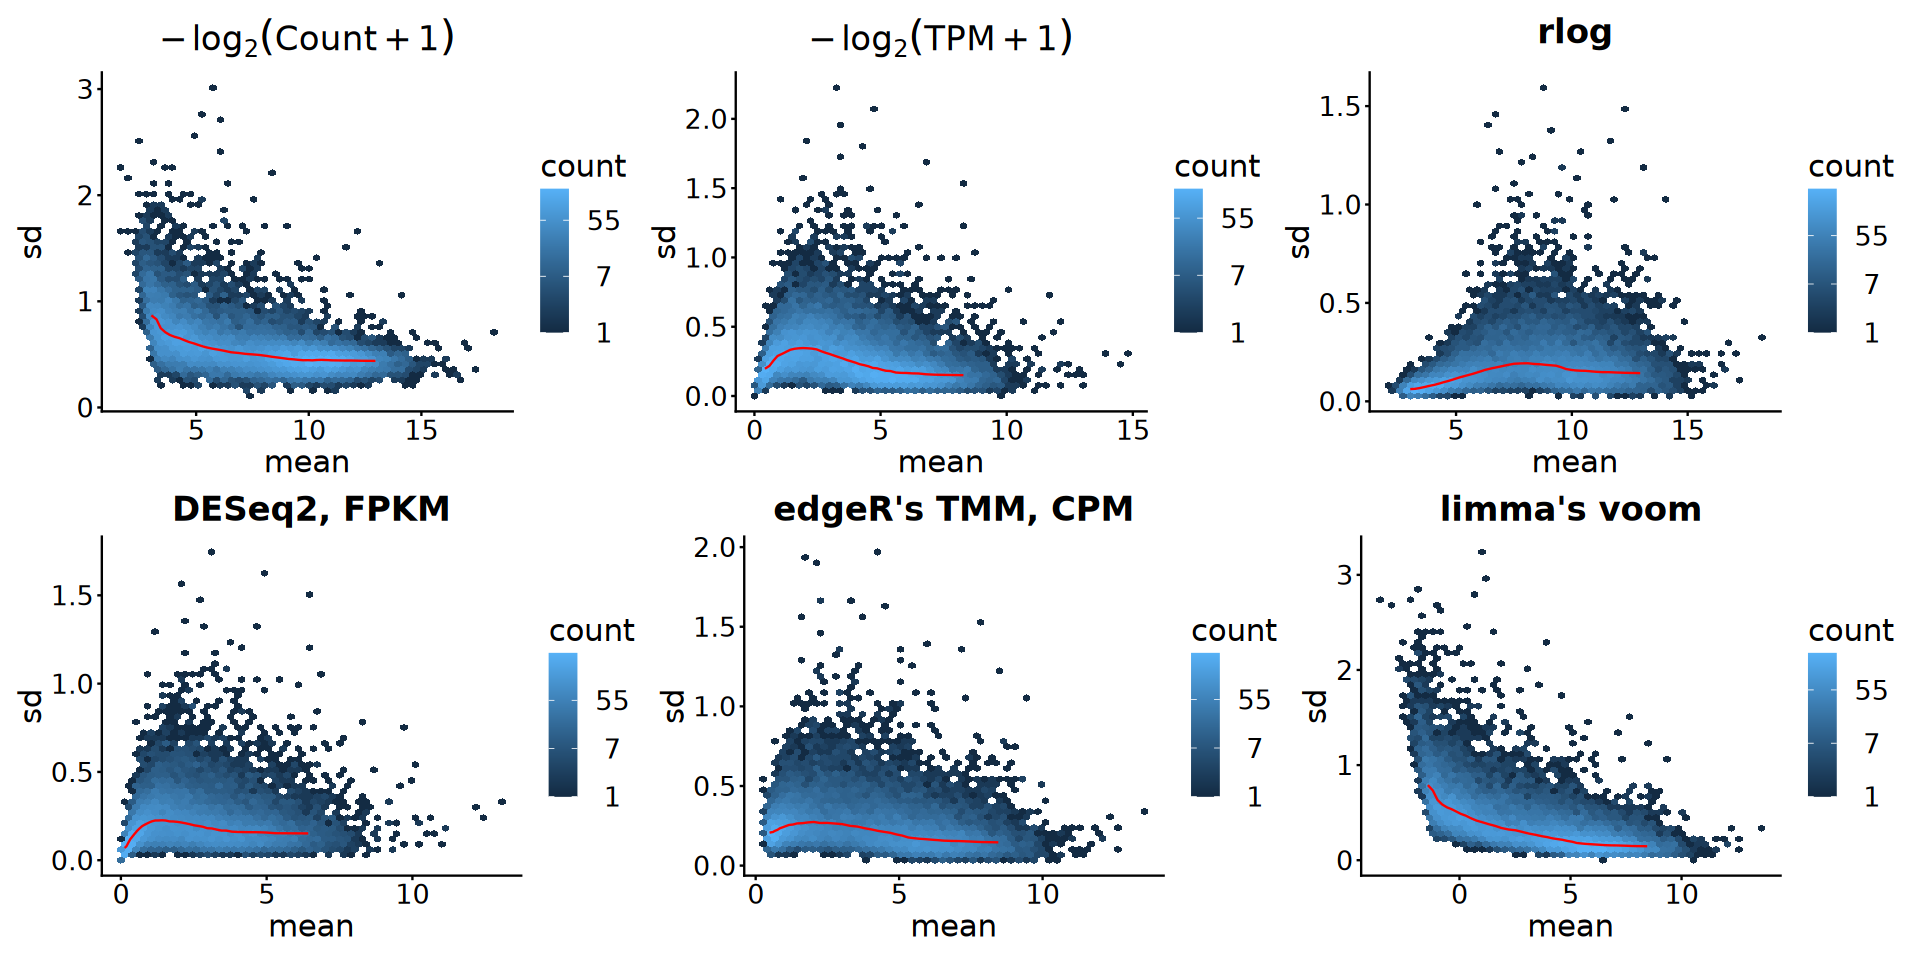

In [38]:
options(repr.plot.width = 16, repr.plot.height = 8)
(p1 + p2 + p3) / (p4 + p5 + p6)

# 4. Exploration

In [39]:
norm_mat <- log2(tpm + 1)
norm_vs <- assay(rld)

### 1). Overview

In [40]:
plot_df <- colData(eSet) |> as.data.frame() |>
    arrange(Genotype, Replicate) |> 
    rownames_to_column(var = "Sample") |>
    mutate(librarySize = colSums(assay(eSet))[Sample])

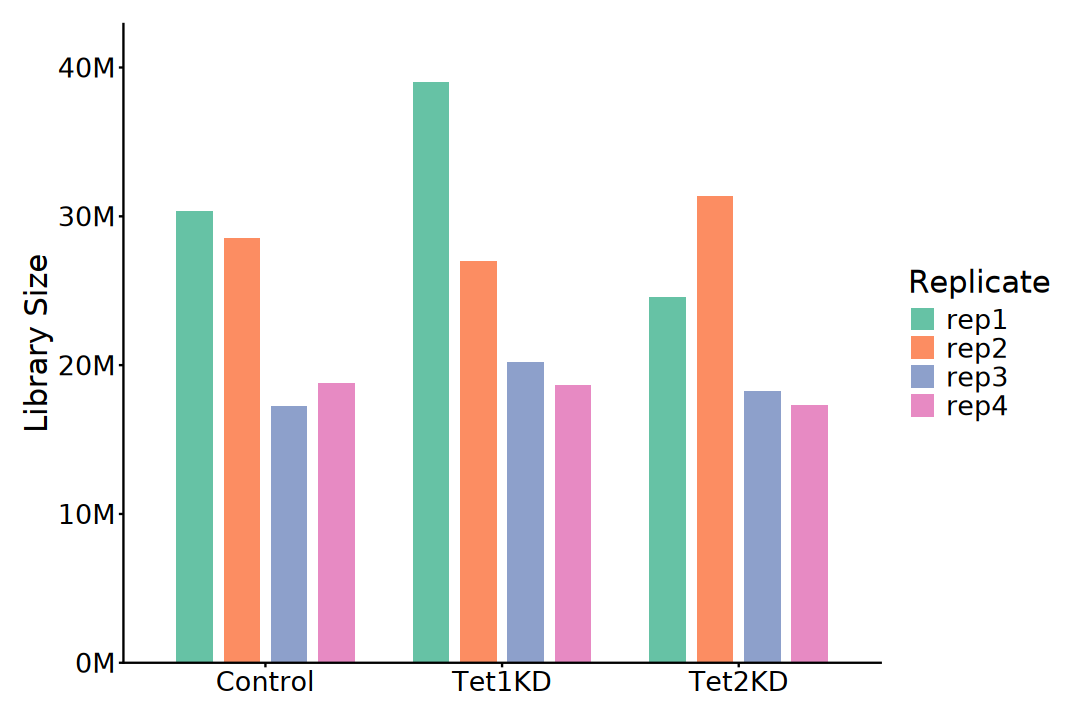

In [41]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = Genotype, y = librarySize, group = Replicate)) +
    geom_bar(
        aes(fill = Replicate), stat = "identity",
        position = position_dodge(width = 0.8),
        width = 0.6, linewidth = 1.5) +
    scale_y_continuous(
        labels = scales::label_number(scale = 1e-6, suffix = "M"),
        limits = c(0, NA), expand = expansion(mult = c(0, 0.1))) +
    scale_fill_brewer(palette = "Set2") +
    labs(x = NULL, y = "Library Size") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.position = "right",
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

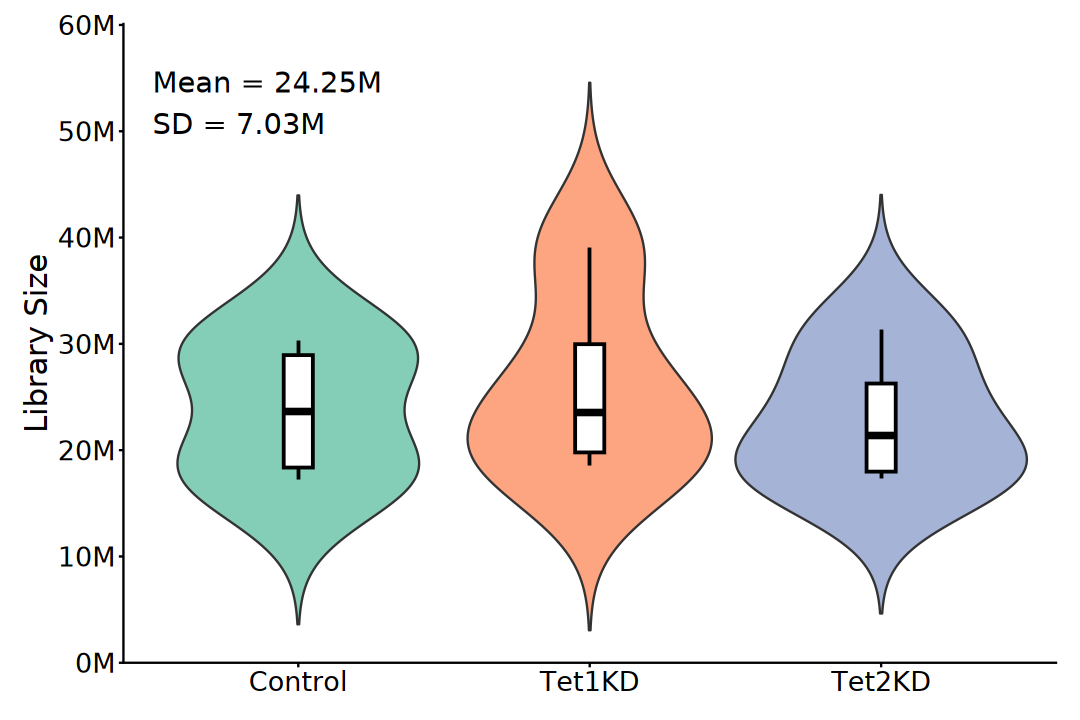

In [42]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = Genotype, y = librarySize)) +
    geom_violin(
        aes(fill = Genotype), width = 1, alpha = 0.8,
        trim = FALSE, show.legend = FALSE) +
    geom_boxplot(
        color = "black", fill = "white", width = 0.1, 
        linewidth = 0.8, show.legend = FALSE) +
    annotate(
        geom = "text", x = .5, y = max(plot_df$librarySize) * 1.4,
        label = paste0("Mean = ", round(mean(plot_df$librarySize) / 1e6 , 2), "M"),
        hjust = 0, size = 6) +
    annotate(
        geom = "text", x = .5, y = max(plot_df$librarySize) * 1.3,
        label = paste0("SD = ", round(sd(plot_df$librarySize) * 1e-6 , 2), "M"),
        hjust = 0, size = 6) +
    scale_y_continuous(
        labels = scales::label_number(scale = 1e-6, suffix = "M"), 
        limits = c(0, NA), expand = expansion(mult = c(0, 0.1))) +
    scale_fill_brewer(palette = "Set2") +
    labs(x = NULL, y = "Library Size") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 2). PCA

In [43]:
top_var_idx <- norm_mat |>
    rowSds() |>
    # (\(m) rowSds(m) / rowMeans2(m))() |> # CV
    tibble::enframe(name = "row", value = "sd") |>
    slice_max(order_by = sd, n = 2000) |>
    pull(row)
# CV can eliminate the bias that "high abundance tends to have large variance".

In [44]:
pca_res <- norm_mat[top_var_idx, ] |> t() |> 
    prcomp(center = TRUE, scale. = FALSE)

per_var <- round(100 * pca_res$sdev^2 / sum(pca_res$sdev^2), 2)

pca_df <- merge(pca_res$x, colData(eSet), by = "row.names")

In [45]:
p1 <- ggplot(pca_df, aes(PC1, PC2)) +
    geom_point(aes(color = Genotype, shape = Replicate), size = 5) +
    scale_color_brewer(palette = "Set1") +
    labs(
        title = bquote("PCA for" ~ -log[2](TPM+1)), 
        x = paste0("PC1: ", per_var[1], "% variance"),
        y = paste0("PC2: ", per_var[2], "% variance")) +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [46]:
pca_res <- plotPCA(
    rld, intgroup = c("Genotype", "Replicate"), 
    ntop = 2000, returnData = TRUE)

per_var <- round(100 * attr(pca_res, "percentVar"))

using ntop=2000 top features by variance



In [47]:
p2 <- ggplot(pca_res, aes(PC1, PC2)) +
    geom_point(aes(color = Genotype, shape = Replicate), size = 5) +
    scale_color_brewer(palette = "Set1") +
    labs(
        title = "PCA for rlog", 
        x = paste0("PC1: ", per_var[1], "% variance"),
        y = paste0("PC2: ", per_var[2], "% variance")) +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [48]:
# Generalized principal component analysis (GLM-PCA)
# suppressPackageStartupMessages(library(glmpca))
gpca <- glmpca::glmpca(assay(eSet)[top_var_idx, ], L = 2)

gpca_df <- merge(gpca$factors, colData(eSet), by = "row.names")

In [49]:
p3 <- ggplot(gpca_df, aes(dim1, dim2)) +
    geom_point(aes(color = Genotype, shape = Replicate), size = 5) +
    scale_color_brewer(palette = "Set1") +
    labs(title = "GLM-PCA for raw count", x = "PC1", y = "PC2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

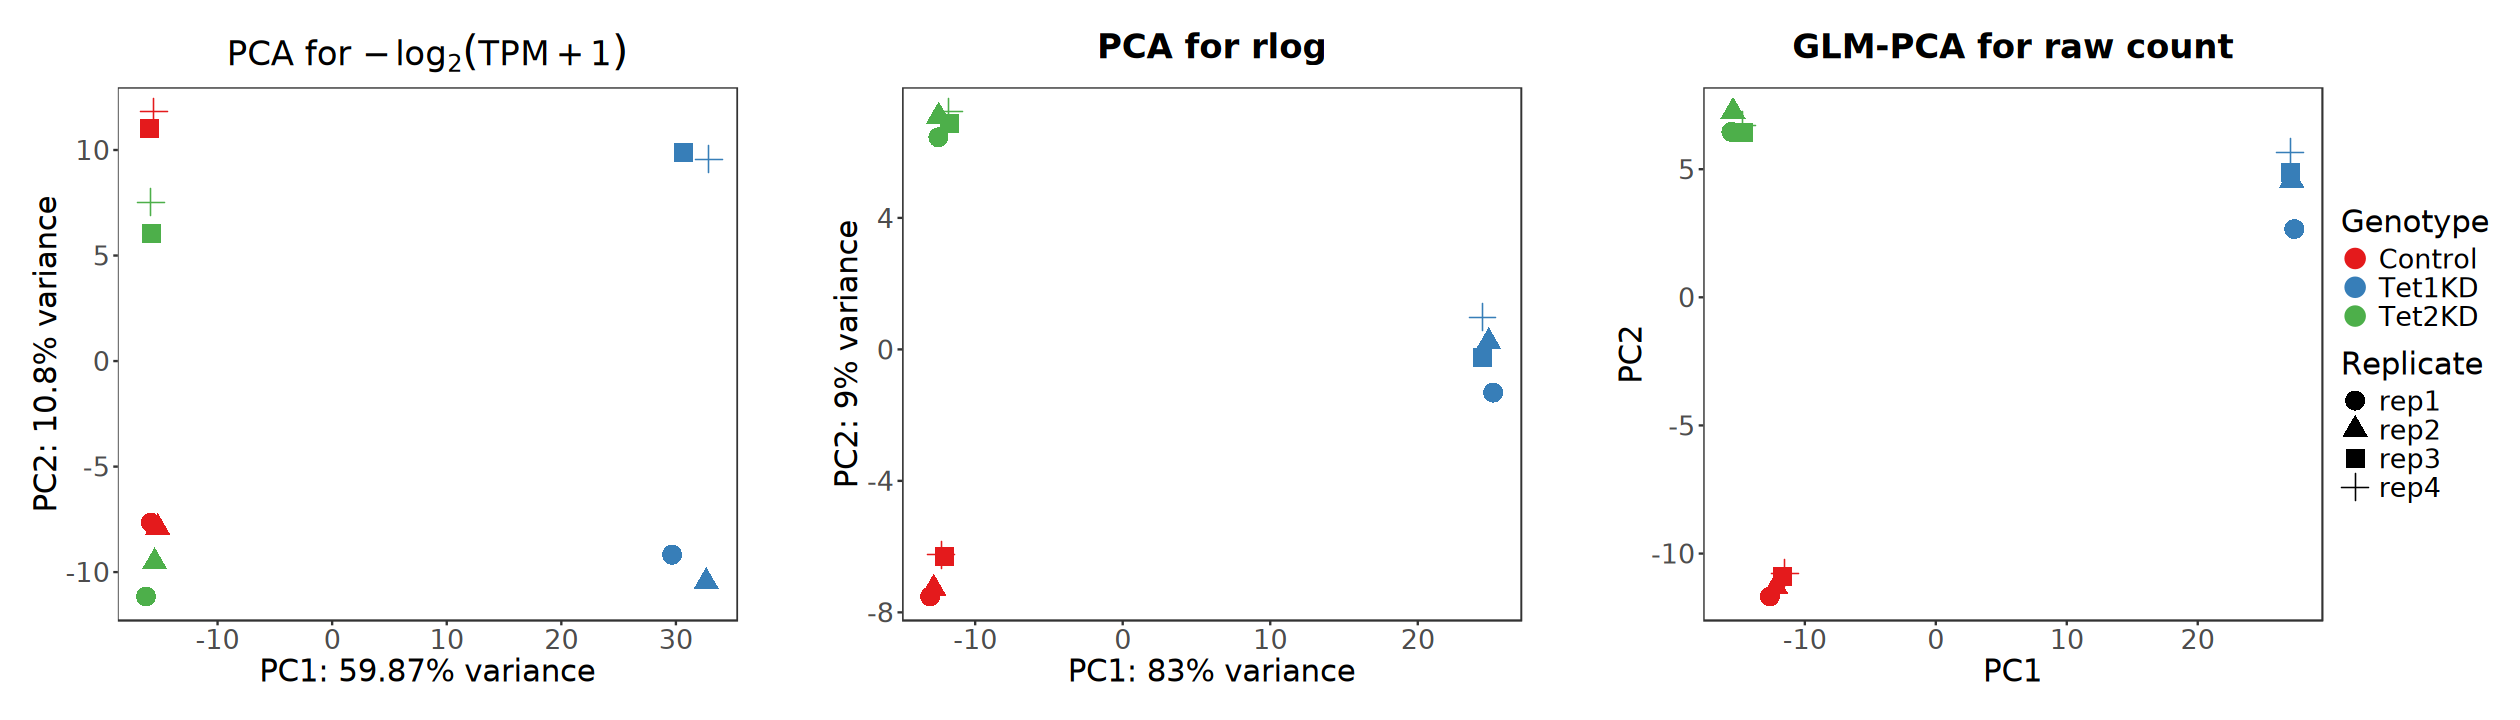

In [50]:
options(repr.plot.width = 21, repr.plot.height = 6)

p1 + plot_spacer() + p2 + plot_spacer() + p3 +
    plot_layout(nrow = 1, guides = "collect", 
                widths = c(1, 0.05, 1, 0.05, 1))

## 3). MDS

> Multidimensional scaling

In [51]:
dist_mat <- norm_vs[top_var_idx, ] |> t() |> dist()

mds <- colData(eSet) |> as.data.frame() |>
    cbind(cmdscale(as.matrix(dist_mat)))

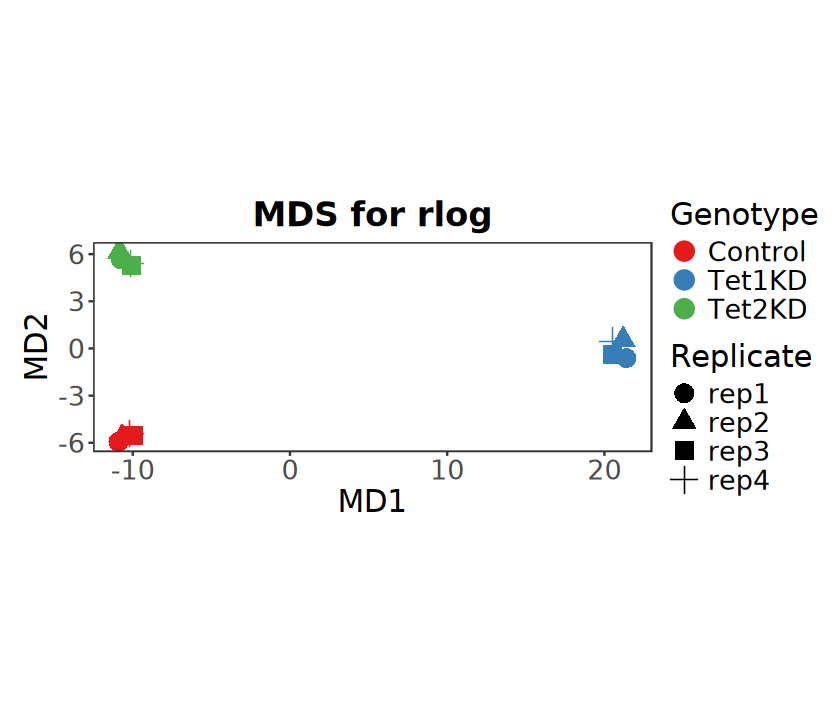

In [ ]:
options(repr.plot.width = 7, repr.plot.height = 6)

ggplot(mds, aes(x = `1`, y = `2`)) +
    geom_point(aes(color = Genotype, shape = Replicate), size = 5) +
    scale_color_brewer(palette = "Set1") +
    coord_fixed() + 
    labs(title = "MDS for rlog", x = "MD1", y = "MD2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 4). PCoA

> Principal coordinate analysis

In [53]:
# 1. Calculate Bray-Curtis distance on the transposed count matrix
dist_mat <- norm_vs[top_var_idx, ] |> t() |> 
    vegan::vegdist(method = "bray")

# 2. Run PCoA
pcoa_res <- cmdscale(dist_mat, k = 2, eig = TRUE)

# 3. Prepare data for plot
pcoa_df <- merge(pcoa_res$points, colData(eSet), by = "row.names")

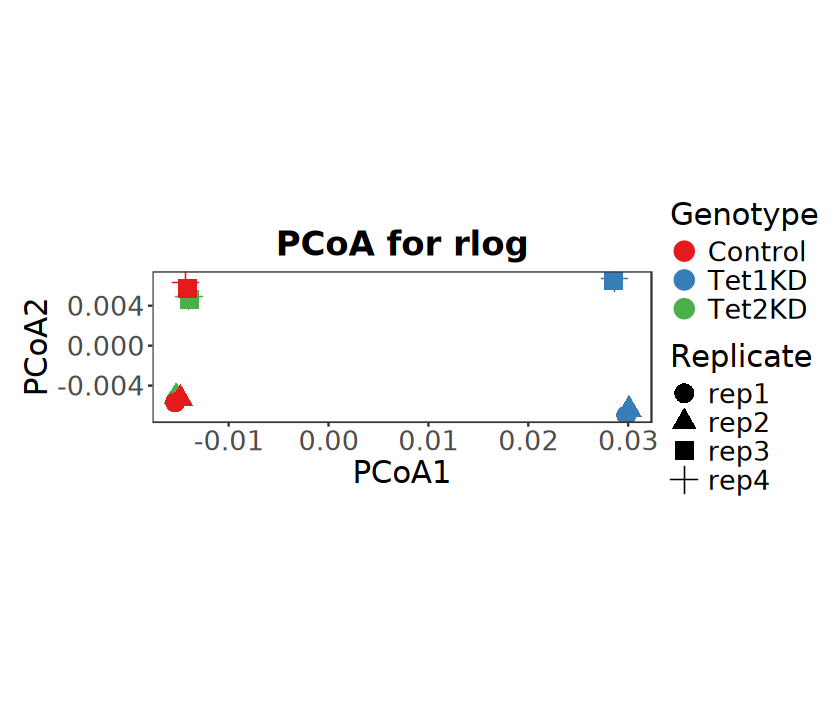

In [54]:
options(repr.plot.width = 7, repr.plot.height = 6)

ggplot(pcoa_df, aes(x = V1, y = V2)) +
    geom_point(aes(color = Genotype, shape = Replicate), size = 5) +
    scale_color_brewer(palette = "Set1") +
    coord_fixed() + 
    # ggtitle(bquote("PCoA for" ~ -log[2](TPM+1))) + 
    ggtitle("PCoA for rlog") + 
    labs(x = "PCoA1", y = "PCoA2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 5). Sample Distance

In [55]:
ac <- colData(eSet) |> as.data.frame() |>
    dplyr::select(Replicate, Genotype)

In [56]:
group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(eSet$Genotype)),
    levels(eSet$Genotype))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(eSet$Replicate)),
    levels(eSet$Replicate))

anno_colors <- list(
    Genotype = group_colors,
    Replicate = replicate_colors)

colors <- colorRampPalette(brewer.pal(9, "Blues"))(255)

In [57]:
dist_mat <- norm_vs[top_var_idx, ] |> t() |> dist()

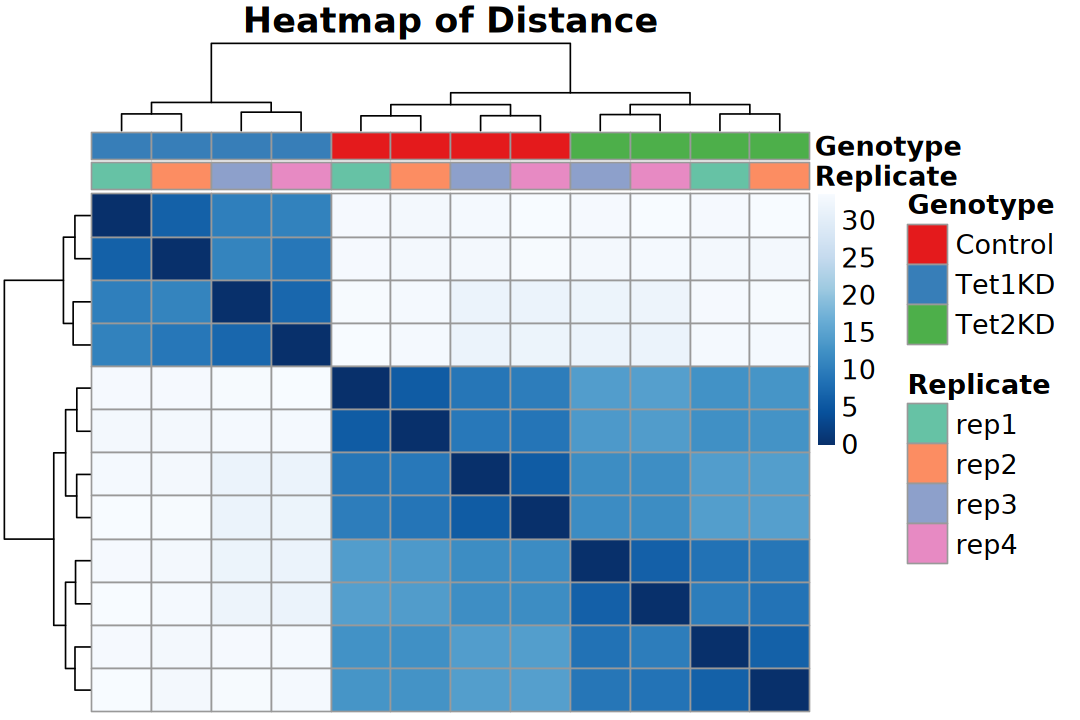

In [58]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(dist_mat),
    clustering_distance_rows = dist_mat,
    clustering_distance_cols = dist_mat,
    annotation_col = ac, col = rev(colors), 
    annotation_colors = anno_colors,
    main = "Heatmap of Distance", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

In [59]:
# This measure of dissimilarity between counts also takes the inherent variance structure 
# of counts into consideration when calculating the distances between samples. 
# The PoissonDistance function takes the original count matrix (not normalized) with samples
# as rows instead of columns, so we need to transpose the counts in dds.
# Calculating sample distances is to use the Poisson Distance

# suppressPackageStartupMessages(library(PoiClaClu))
poisd <- assay(eSet)[top_var_idx, ] |> t() |> 
    PoiClaClu::PoissonDistance()

dist_mat <- poisd$dd |> as.matrix()

colnames(dist_mat) <- colnames(eSet)

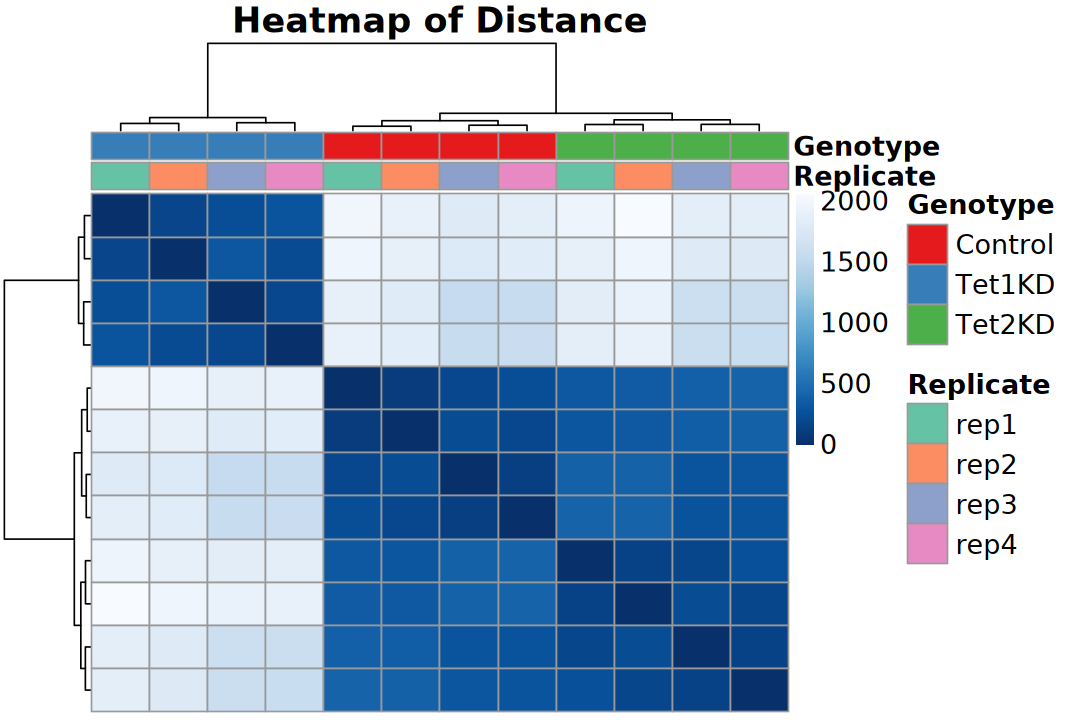

In [60]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(dist_mat),
    clustering_distance_rows = poisd$dd,
    clustering_distance_cols = poisd$dd,
    annotation_col = ac, col = rev(colors), 
    annotation_colors = anno_colors,
    main = "Heatmap of Distance", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

## 6). Sample Correlation

In [61]:
cor_mat <- cor(norm_vs[top_var_idx, ], method = "spearman")

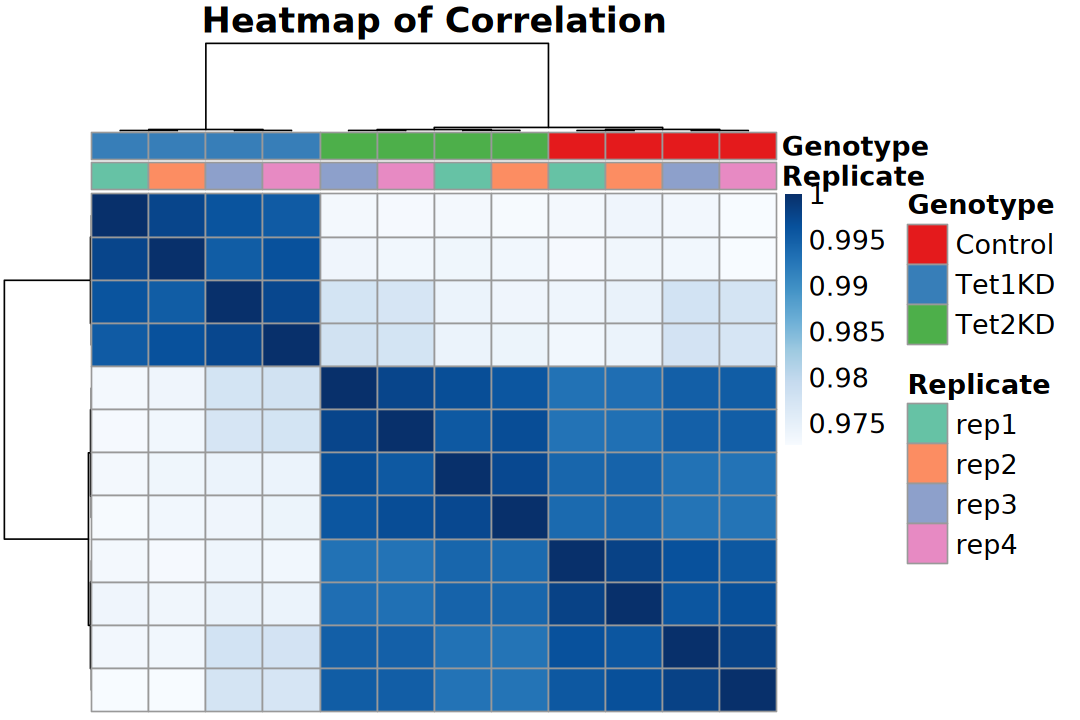

In [62]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(cor_mat), 
    clustering_distance_rows = "correlation",
    clustering_distance_cols = "correlation",
    annotation_col = ac, col = colors, 
    annotation_colors = anno_colors,
    main = "Heatmap of Correlation", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

## 7). Heatmap

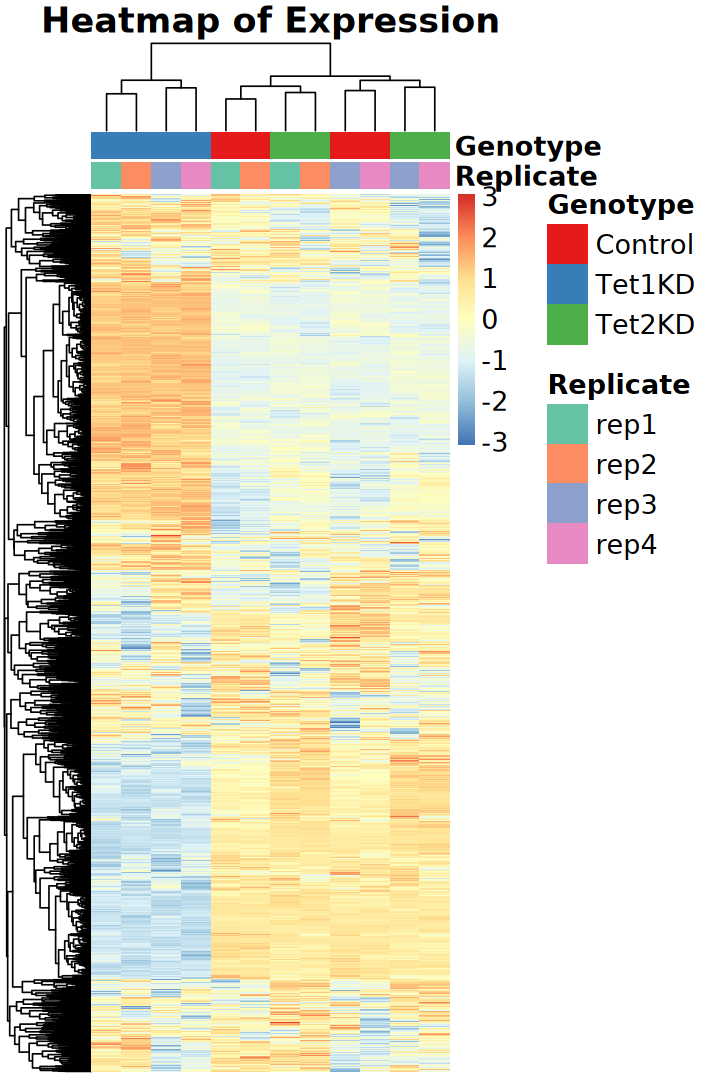

In [63]:
options(repr.plot.width = 6, repr.plot.height = 9)

pheatmap::pheatmap(
    norm_mat[top_var_idx, ], scale = "row", 
    annotation_col = ac, 
    annotation_colors = anno_colors, 
    main = "Heatmap of Expression", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

# 5. DEGs

In [64]:
logfc_cutoff <- log2(2)
p_cutoff <- 0.05

## 1). DESeq2

> median of ratios for normalization

In [65]:
design(dds)

~Batch + Genotype

In [66]:
dds <- DESeq(dds)

using pre-existing size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



In [67]:
resultsNames(dds)

[1] "Intercept"                  "Batch_batch2_vs_batch1"    
[3] "Genotype_Tet1KD_vs_Control" "Genotype_Tet2KD_vs_Control"

In [68]:
coef_label <- resultsNames(dds)[3:4]
contrast_labels <- sub("^Genotype_", "", coef_label)
contrast_labels

[1] "Tet1KD_vs_Control" "Tet2KD_vs_Control"

### a). Standard

In [69]:
deseq2_result_list <- map(coef_label, function(coef) {
    results(dds, name = coef) |>
        as.data.frame() |> 
        rownames_to_column("gene_id") |>
        dplyr::rename(logFC = log2FoldChange) |>
        mutate(
            method = "DESeq2",
            contrast = sub("^Genotype_", "", coef),
            result = case_when(
                padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
                padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
                TRUE ~ "NS"
            ) |> factor(levels = c("Up", "Down", "NS"))) |>
        left_join(
            rowData(dds) |> as.data.frame() |> 
                dplyr::select(symbol, type, basepairs) |>
                rownames_to_column("gene_id"), 
            by = "gene_id")
}) |> set_names(contrast_labels)

In [70]:
deseq2_result_df <- bind_rows(deseq2_result_list) |>
    group_by(contrast, result) |>
    arrange(padj, logFC |> abs() |> desc()) |>
    mutate(
        label = ifelse(
            type == "protein_coding" & 
                result %in% c("Up", "Down") & 
                row_number() <= 5, 
            symbol, NA_character_)) |>
    ungroup() |>
    mutate(contrast = factor(contrast, levels = contrast_labels))

table(deseq2_result_df$contrast, deseq2_result_df$result)

                   
                       Up  Down    NS
  Tet1KD_vs_Control  1020  1096 16590
  Tet2KD_vs_Control   153   138 18415

### b). LFC Shrink

> Shrinkage of effect size (LFC estimates) is useful for visualization and ranking of genes.
>
> Notes:
> - `apeglm` shrunken LFC requires specific coefficients from resultsNames(dds). Re-leveling the reference group is necessary to compute contrasts not inherently present in the initial design matrix.

In [71]:
deseq2_lfc_result_list <- map(coef_label, function(coef) {
    lfcShrink(dds, coef = coef, type = "apeglm") |>
        as.data.frame() |> 
        rownames_to_column("gene_id") |>
        dplyr::rename(logFC = log2FoldChange) |>
        mutate(
            method = "DESeq2-lfcShrink",
            contrast = sub("^Genotype_", "", coef),
            result = case_when(
                padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
                padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
                TRUE ~ "NS"
            ) |> factor(levels = c("Up", "Down", "NS"))) |>
        left_join(
            rowData(dds) |> as.data.frame() |> 
                dplyr::select(symbol, type, basepairs) |>
                rownames_to_column("gene_id"), 
            by = "gene_id")
}) |> set_names(contrast_labels)

using 'apeglm' for LFC shrinkage. If used in published research, please cite:
    Zhu, A., Ibrahim, J.G., Love, M.I. (2018) Heavy-tailed prior distributions for
    sequence count data: removing the noise and preserving large differences.
    Bioinformatics. https://doi.org/10.1093/bioinformatics/bty895

using 'apeglm' for LFC shrinkage. If used in published research, please cite:
    Zhu, A., Ibrahim, J.G., Love, M.I. (2018) Heavy-tailed prior distributions for
    sequence count data: removing the noise and preserving large differences.
    Bioinformatics. https://doi.org/10.1093/bioinformatics/bty895



In [72]:
deseq2_lfc_result_df <- bind_rows(deseq2_lfc_result_list) |>
    group_by(contrast, result) |>
    arrange(padj, logFC |> abs() |> desc()) |>
    mutate(
        label = ifelse(
            type == "protein_coding" & 
                result %in% c("Up", "Down") & 
                row_number() <= 5, 
            symbol, NA_character_)) |>
    ungroup() |>
    mutate(contrast = factor(contrast, levels = contrast_labels))

table(deseq2_lfc_result_df$contrast, deseq2_lfc_result_df$result)

                   
                       Up  Down    NS
  Tet1KD_vs_Control   859   923 16924
  Tet2KD_vs_Control    74    70 18562

In [73]:
comparison_df <- deseq2_result_df |> 
    dplyr::select(gene_id, contrast, result_raw = result) |> 
    inner_join(
        deseq2_lfc_result_df |> 
            dplyr::select(gene_id, contrast, result_lfc = result),
        by = c("gene_id", "contrast"))

comparison_df |> 
    group_split(contrast) |> 
    walk(function(sub_df) {
        cat("\n=========================================\n")
        cat("Contrast:", as.character(unique(sub_df$contrast)), "\n")
        cat("=========================================\n")
        print(table(Raw = sub_df$result_raw, LFC_Shrink = sub_df$result_lfc))
    })


Contrast: Tet1KD_vs_Control 
      LFC_Shrink
Raw       Up  Down    NS
  Up     859     0   161
  Down     0   923   173
  NS       0     0 16590

Contrast: Tet2KD_vs_Control 
      LFC_Shrink
Raw       Up  Down    NS
  Up      74     0    79
  Down     0    70    68
  NS       0     0 18415


## 2). edgeR

> Trimmed Mean of M-values (TMM)

In [74]:
design <- model.matrix(~ group + Batch, data = dgel$samples)
design

,(Intercept),groupTet1KD,groupTet2KD,Batchbatch2
Tets_Ctrl_rep1,1,0,0,0
Tets_Ctrl_rep2,1,0,0,0
Tets_Ctrl_rep3,1,0,0,1
Tets_Ctrl_rep4,1,0,0,1
Tet1_KD_rep1,1,1,0,0
Tet1_KD_rep2,1,1,0,0
Tet1_KD_rep3,1,1,0,1
Tet1_KD_rep4,1,1,0,1
Tet2_KD_rep1,1,0,1,0
Tet2_KD_rep2,1,0,1,0


In [75]:
contrast_matrix <- makeContrasts(
    Tet1KD_vs_Control = groupTet1KD,
    Tet2KD_vs_Control = groupTet2KD,
    levels = design)
contrast_matrix

contrast_labels <- colnames(contrast_matrix)
contrast_labels

Renaming (Intercept) to Intercept



,Tet1KD_vs_Control,Tet2KD_vs_Control
Intercept,0,0
groupTet1KD,1,0
groupTet2KD,0,1
Batchbatch2,0,0


[1] "Tet1KD_vs_Control" "Tet2KD_vs_Control"

### a). Negative binomial GLM framework

In [76]:
dgel <- estimateDisp(dgel, design)
# likelihood ratio test
fit <- glmFit(dgel, design)

In [77]:
edger_result_list <- map(colnames(contrast_matrix), function(idx) {
    glmLRT(fit, contrast = contrast_matrix[, idx]) |>
        topTags(n = Inf) |>
        as.data.frame() |>
        rownames_to_column("gene_id") |>
        dplyr::rename(padj = FDR, pvalue = PValue) |>
        mutate(
            method = "edgeR-lrt",
            contrast = idx,
            result = case_when(
                padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
                padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
                TRUE ~ "NS"
            ) |> factor(levels = c("Up", "Down", "NS")))
}) |> set_names(contrast_labels)

In [78]:
edger_result_df <- bind_rows(edger_result_list) |>
    group_by(contrast, result) |>
    arrange(padj, logFC |> abs() |> desc()) |>
    mutate(
        label = ifelse(
            type == "protein_coding" & 
                result %in% c("Up", "Down") & 
                row_number() <= 5, 
            symbol, NA_character_)) |>
    ungroup() |>
    mutate(contrast = factor(contrast, levels = contrast_labels))

table(edger_result_df$contrast, edger_result_df$result)

                   
                       Up  Down    NS
  Tet1KD_vs_Control  1012  1109 16091
  Tet2KD_vs_Control   196   178 17838

### b). Quasi-likelihood pipeline (edgeR v3)

In [79]:
dgel <- estimateDisp(dgel, design)
# quasi-likelihood (QL) F-test
fit <- glmQLFit(dgel, design)

In [80]:
edger_qlf_result_list <- map(colnames(contrast_matrix), function(idx) {
    glmQLFTest(fit, contrast = contrast_matrix[, idx]) |>
        topTags(n = Inf) |>
        as.data.frame() |>
        rownames_to_column("gene_id") |>
        dplyr::rename(padj = FDR, pvalue = PValue) |>
        mutate(
            method = "edgeR-lrt",
            contrast = idx,
            result = case_when(
                padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
                padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
                TRUE ~ "NS"
            ) |> factor(levels = c("Up", "Down", "NS")))
}) |> set_names(contrast_labels)

In [81]:
edger_qlf_result_df <- bind_rows(edger_qlf_result_list) |>
    group_by(contrast, result) |>
    arrange(padj, logFC |> abs() |> desc()) |>
    mutate(
        label = ifelse(
            type == "protein_coding" & 
                result %in% c("Up", "Down") & 
                row_number() <= 5, 
            symbol, NA_character_)) |>
    ungroup() |>
    mutate(contrast = factor(contrast, levels = contrast_labels))

table(edger_qlf_result_df$contrast, edger_qlf_result_df$result)

                   
                       Up  Down    NS
  Tet1KD_vs_Control  1004  1096 16112
  Tet2KD_vs_Control   178   157 17877

In [82]:
comparison_df <- edger_result_df |> 
    dplyr::select(gene_id, contrast, result_lrt = result) |> 
    inner_join(
        edger_qlf_result_df |> 
            dplyr::select(gene_id, contrast, result_qlf = result),
        by = c("gene_id", "contrast"))

comparison_df |> 
    group_split(contrast) |> 
    walk(function(sub_df) {
        cat("\n=========================================\n")
        cat("Contrast:", as.character(unique(sub_df$contrast)), "\n")
        cat("=========================================\n")
        print(table(LRT = sub_df$result_lrt, QLF = sub_df$result_qlf))
    })


Contrast: Tet1KD_vs_Control 
      QLF
LRT       Up  Down    NS
  Up     995     0    17
  Down     0  1082    27
  NS       9    14 16068

Contrast: Tet2KD_vs_Control 
      QLF
LRT       Up  Down    NS
  Up     171     0    25
  Down     0   154    24
  NS       7     3 17828


## 3). limma

> In the limma approach to RNA-seq, read counts are converted to log2-counts-per-million (logCPM), and the mean-variance relationship is modeled either with precision weights or with an empirical Bayes prior trend. The precision weights approach is called “voom,” and the prior trend approach is called “limma-trend.”

In [83]:
design <- model.matrix(~ group + Batch, data = dgel$samples)

In [84]:
contrast_matrix <- makeContrasts(
    Tet1KD_vs_Control = groupTet1KD,
    Tet2KD_vs_Control = groupTet2KD,
    levels = design)
contrast_matrix

contrast_labels <- colnames(contrast_matrix)
contrast_labels

Renaming (Intercept) to Intercept



,Tet1KD_vs_Control,Tet2KD_vs_Control
Intercept,0,0
groupTet1KD,1,0
groupTet2KD,0,1
Batchbatch2,0,0


[1] "Tet1KD_vs_Control" "Tet2KD_vs_Control"

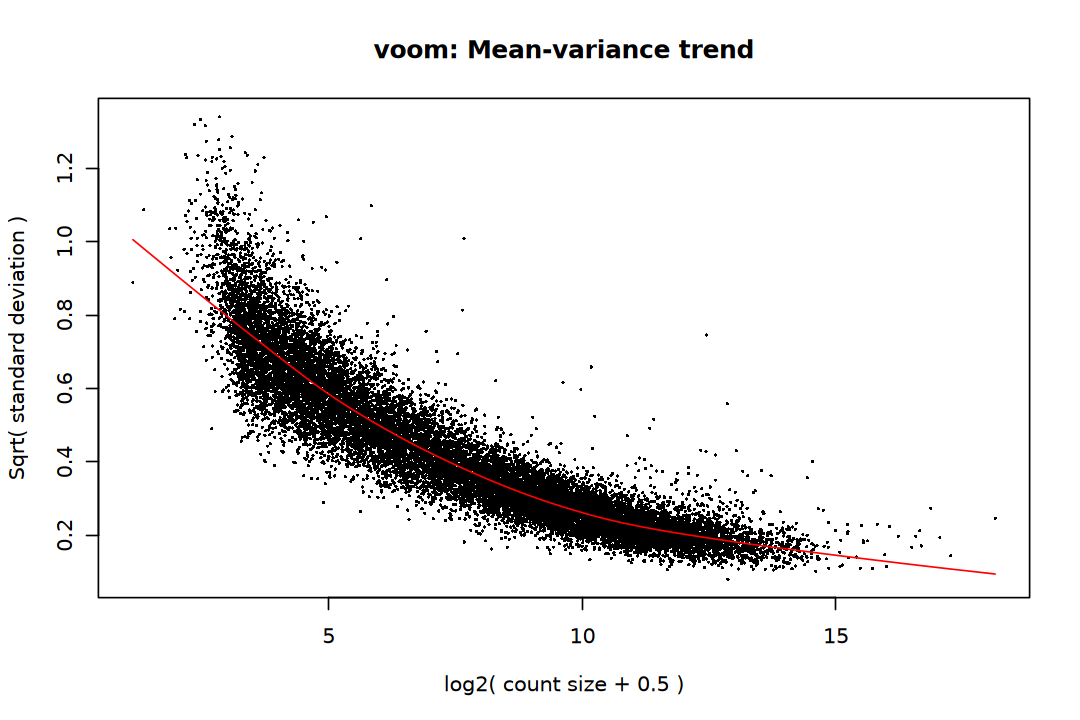

In [85]:
options(repr.plot.width = 9, repr.plot.height = 6)

norm_v <- voom(dgel, design, plot = TRUE)

In [86]:
# Linear Model for Series of Arrays
fit <- lmFit(norm_v, design)
# Compute contrasts from linear model fit
fit <- contrasts.fit(fit, contrast_matrix)
# Empirical Bayes Statistics for Differential Expression
fit <- eBayes(fit)

In [87]:
limma_result_list <- map(colnames(contrast_matrix), function(idx) {
    topTable(fit, coef = idx, number = Inf) |>
        as.data.frame() |>
        rownames_to_column("gene_id") |>
        dplyr::rename(padj = adj.P.Val, pvalue = P.Value) |>
        mutate(
            method = "limma",
            contrast = idx,
            result = case_when(
                padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
                padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
                TRUE ~ "NS"
            ) |> factor(levels = c("Up", "Down", "NS")))
}) |> set_names(contrast_labels)

In [88]:
limma_result_df <- bind_rows(limma_result_list) |>
    group_by(contrast, result) |>
    arrange(padj, logFC |> abs() |> desc()) |>
    mutate(
        label = ifelse(
            type == "protein_coding" & 
                result %in% c("Up", "Down") & 
                row_number() <= 5, 
            symbol, NA_character_)) |>
    ungroup() |>
    mutate(contrast = factor(contrast, levels = contrast_labels))

table(limma_result_df$contrast, limma_result_df$result)

                   
                       Up  Down    NS
  Tet1KD_vs_Control  1006  1112 16094
  Tet2KD_vs_Control   175   163 17874

In [89]:
comparison_df <- edger_qlf_result_df |> 
    dplyr::select(gene_id, contrast, result_edger = result) |> 
    inner_join(
        limma_result_df |> 
            dplyr::select(gene_id, contrast, result_limma = result),
        by = c("gene_id", "contrast"))

comparison_df |> 
    group_split(contrast) |> 
    walk(function(sub_df) {
        cat("\n=========================================\n")
        cat("Contrast:", as.character(unique(sub_df$contrast)), "\n")
        cat("=========================================\n")
        print(table(edgeR = sub_df$result_edger, Limma = sub_df$result_limma))
    })


Contrast: Tet1KD_vs_Control 
      Limma
edgeR     Up  Down    NS
  Up     981     0    23
  Down     0  1074    22
  NS      25    38 16049

Contrast: Tet2KD_vs_Control 
      Limma
edgeR     Up  Down    NS
  Up     160     0    18
  Down     0   148     9
  NS      15    15 17847


## DEGs Evaluation

In [90]:
all_results <- bind_rows(
    deseq2_result_df, edger_qlf_result_df, limma_result_df)

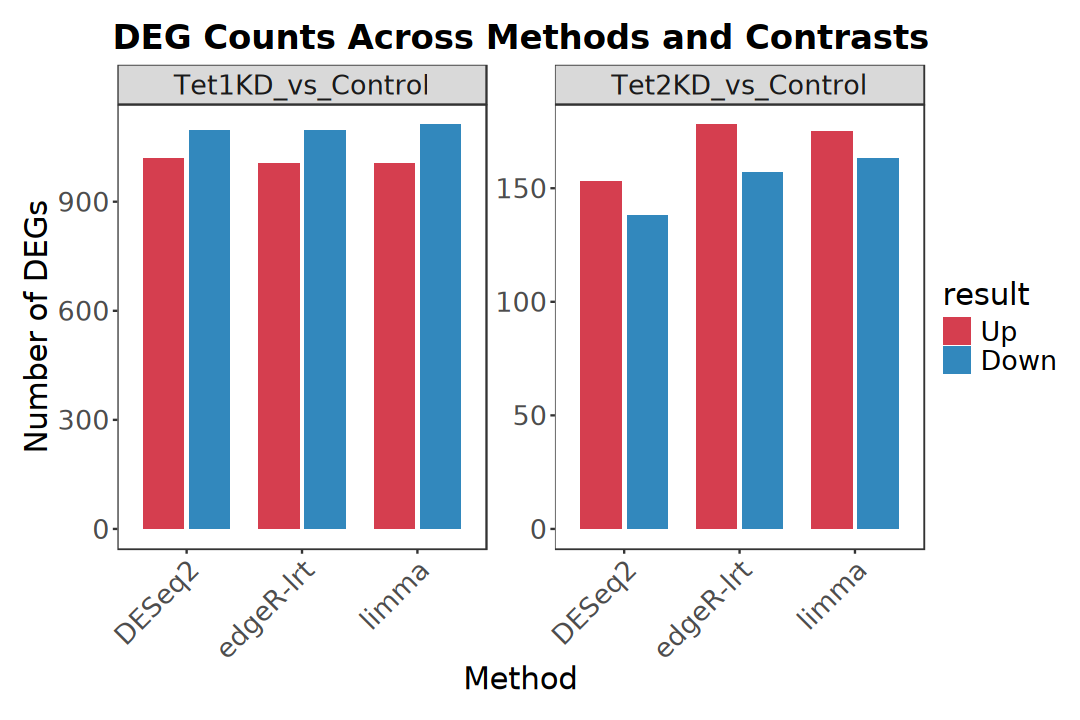

In [91]:
options(repr.plot.width = 9, repr.plot.height = 6)

all_results |> filter(result != "NS") |> 
    dplyr::count(method, contrast, result) |>
    ggplot(aes(x = method, y = n, fill = result)) +
        geom_col(position = position_dodge(width = 0.8), width = 0.7) +
        facet_wrap(~ contrast, scales = "free_y") +
        scale_fill_manual(
            values = c("Up" = "#D53E4F", "Down" = "#3288BD")) +
        labs(
            title = "DEG Counts Across Methods and Contrasts", 
            x = "Method", y = "Number of DEGs") +
        theme_test() + 
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            strip.text = element_text(size = 16),
            legend.title = element_text(size = 18), 
            legend.text = element_text(size = 16),
            axis.title = element_text(size = 18), 
            axis.text.x = element_text(size = 16, angle = 45, hjust = 1), 
            axis.text.y = element_text(size = 16))

In [92]:
# ------------------------------------------------------------------------------
# Function: summarize_software_deg_overlaps
#
# Description:
# This function computes and summarizes the overlap composition of DEG sets 
# across different software packages (e.g., DESeq2, edgeR, limma) within a contrast.
# ------------------------------------------------------------------------------
summarize_software_deg_overlaps <- function(prefix, deg_list) {
    sample_names <- grep(
        paste0("^", prefix, "_"), names(deg_list), value = TRUE)
    software_id <- str_replace_all(
        sample_names, paste0(prefix, "_"), "")
    
    comb_levels <- unlist(lapply(seq_along(software_id), function(i) {
        combn(software_id, i, FUN = function(x) 
            paste(x, collapse = "&"), simplify = TRUE)
    }), use.names = FALSE)
    
    current_list <- deg_list[sample_names]
    names(current_list) <- software_id
    
    all_genes <- unique(unlist(current_list))
    
    venn_grid <- expand.grid(rep(list(c(0, 1)), length(software_id))) |> 
        set_names(software_id)
    
    counts_df <- map_dfc(current_list, ~ as.integer(all_genes %in% .x)) |> 
        group_by(across(all_of(software_id))) |> 
        summarise(Counts = n(), .groups = "drop")
    
    venn_grid |> left_join(counts_df, by = software_id) |> 
        mutate(Counts = replace_na(Counts, 0)) |> rowwise() |> 
        mutate(
            Combination = {
                vals <- c_across(all_of(software_id))
                present <- software_id[vals == 1]
                if (length(present) == 0) "none" else 
                paste(present, collapse = "&")
            } |> factor(levels = comb_levels), 
            Group = prefix) |> 
        ungroup() |> 
        filter(Combination != "none") |> 
        dplyr::select(Group, Combination, Counts) |> 
        as.data.frame()
}

In [93]:
deg_list <- all_results |> filter(result != "NS") |> 
    mutate(list_name = paste0(contrast, "_", method)) |> 
    group_by(list_name) |> 
    summarise(genes = list(gene_id)) |> 
    deframe()

res_summary <- summarize_software_deg_overlaps("Tet1KD_vs_Control", deg_list)
print(res_summary)

              Group            Combination Counts
1 Tet1KD_vs_Control                 DESeq2     86
2 Tet1KD_vs_Control              edgeR-lrt     20
3 Tet1KD_vs_Control       DESeq2&edgeR-lrt     25
4 Tet1KD_vs_Control                  limma     55
5 Tet1KD_vs_Control           DESeq2&limma      8
6 Tet1KD_vs_Control        edgeR-lrt&limma     58
7 Tet1KD_vs_Control DESeq2&edgeR-lrt&limma   1997


In [94]:
deg_overlap_df <- map(contrast_labels, function(con) {
    summarize_software_deg_overlaps(prefix = con, deg_list = deg_list)}) |> 
    list_rbind()

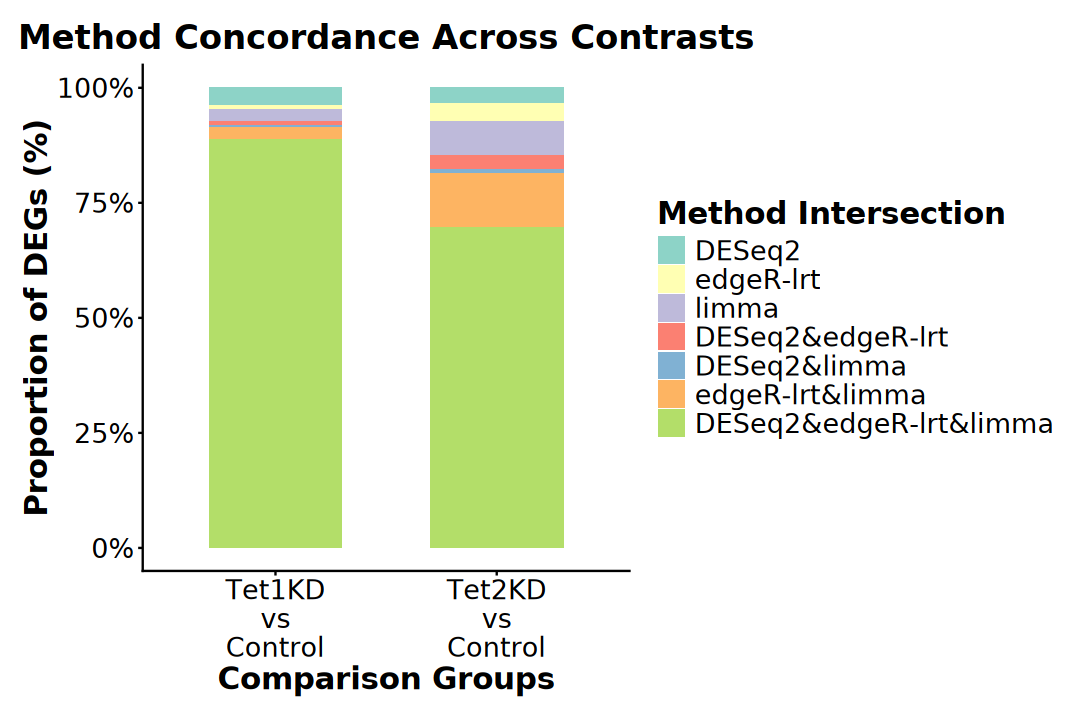

In [95]:
options(repr.plot.width = 9, repr.plot.height = 6)

deg_overlap_df |>
    mutate(Group = str_replace_all(Group, "_", "\n")) |>
    ggplot(aes(x = Group, y = Counts, fill = Combination)) +
        geom_bar(stat = "identity", position = "fill", width = 0.6) +
        scale_y_continuous(labels = scales::percent_format()) + 
        scale_fill_brewer(palette = "Set3") +
        labs(
            title = "Method Concordance Across Contrasts",
            x = "Comparison Groups", 
            y = "Proportion of DEGs (%)",
            fill = "Method Intersection"
        ) +
        theme_classic() +
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
            plot.margin = unit(c(1, 1, 1, 1), "line"), 
            legend.position = "right", 
            legend.title = element_text(size = 18, face = "bold"), 
            legend.text = element_text(size = 16),
            axis.title = element_text(size = 18, face = "bold"), 
            axis.text = element_text(size = 16, color = "black"))

## DEGs Visualization

In [96]:
deg_df <- bind_rows(deseq2_result_list) |>
    group_by(contrast, result) |>
    arrange(padj, logFC |> abs() |> desc()) |>
    mutate(
        label = ifelse(
            type == "protein_coding" & 
                result %in% c("Up", "Down") & 
                row_number() <= 5, 
            symbol, NA_character_)) |>
    ungroup() |>
    mutate(contrast = factor(contrast, levels = contrast_labels))

table(deg_df$contrast, deg_df$result)

                   
                       Up  Down    NS
  Tet1KD_vs_Control  1020  1096 16590
  Tet2KD_vs_Control   153   138 18415

In [97]:
max_logfc <- deg_df$logFC |> abs() |> 
    max(na.rm = TRUE) |> 
    ceiling()

min_padj <- deg_df$padj |> pmax(1e-300) |>
    (\(x) -log10(x))() |>
    max(na.rm = TRUE) |>
    (\(x) ceiling(x / 5) * 5)()

### Multi-group Volcano

In [98]:
p1 <- ggplot(deg_df, aes(x = contrast, y = logFC)) + 
    geom_point(
        aes(color = result, size = result), 
        position = position_jitter(width = 0.4, height = 0), 
        na.rm = TRUE, alpha = 0.6) +
    geom_tile(
        aes(x = contrast, y = 0, fill = contrast), 
        width = 0.9, height = 1.5, show.legend = FALSE) +
    geom_text(
        aes(x = contrast, y = 0, label = contrast), 
        color = "black", size = 6) +
    geom_text_repel(
        aes(label = label), na.rm = TRUE, size = 5, 
        min.segment.length = 0, segment.size = 0.5,
        color = "black", max.overlaps = Inf) +
    scale_fill_brewer(palette = "Set2") + 
    scale_size_manual(
        values = c("Up" = 2, "Down" = 2, "NS" = 1),
        guide = "none") + 
    scale_color_manual(
        name = "DEG",
        values = c(Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
    guides(color = guide_legend(override.aes = list(size = 5))) +
    labs(x = "Comparisons", y = "LogFC") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 20),
        axis.text.x = element_blank(),
        axis.text.y = element_text(size = 16),
        axis.ticks.x = element_blank(),
        axis.line.x = element_blank())

In [99]:
p2 <- ggplot(deg_df, aes(x = contrast, y = logFC)) + 
    geom_point(
        aes(color = logFC, size = result), 
        position = position_jitter(width = 0.4, height = 0), 
        na.rm = TRUE, alpha = 0.6) +
    geom_tile(
        aes(x = contrast, y = 0, fill = contrast), width = 0.9,
        height = 1.5, show.legend = FALSE) +
    geom_text(
        aes(x = contrast, y = 0, label = contrast),
        color = "black", size = 6) +
    geom_text_repel(
        aes(label = label), na.rm = TRUE, size = 5, 
        min.segment.length = 0, segment.size = 0.5,
        color = "black", max.overlaps = Inf) +
    scale_fill_brewer(palette = "Set2") + 
    scale_size_manual(
        values = c("Up" = 2, "Down" = 2, "NS" = 1),
        guide = "none") + 
    scale_color_gradientn(
        name = "logFC",
        colors = c("#39489f","#39bbec","#f9ed36","#f38466","#b81f25"), 
        limits = c(-max_logfc, max_logfc)) +
    # scale_color_viridis_c(
    #     name = "logFC", option = "turbo", begin = 0.1, end = 0.9, 
    #     limits = c(-max_logfc, max_logfc)) + 
    labs(x = "Comparisons", y = "LogFC") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 20),
        axis.text.x = element_blank(),
        axis.text.y = element_text(size = 16),
        axis.ticks.x = element_blank(),
        axis.line.x = element_blank())

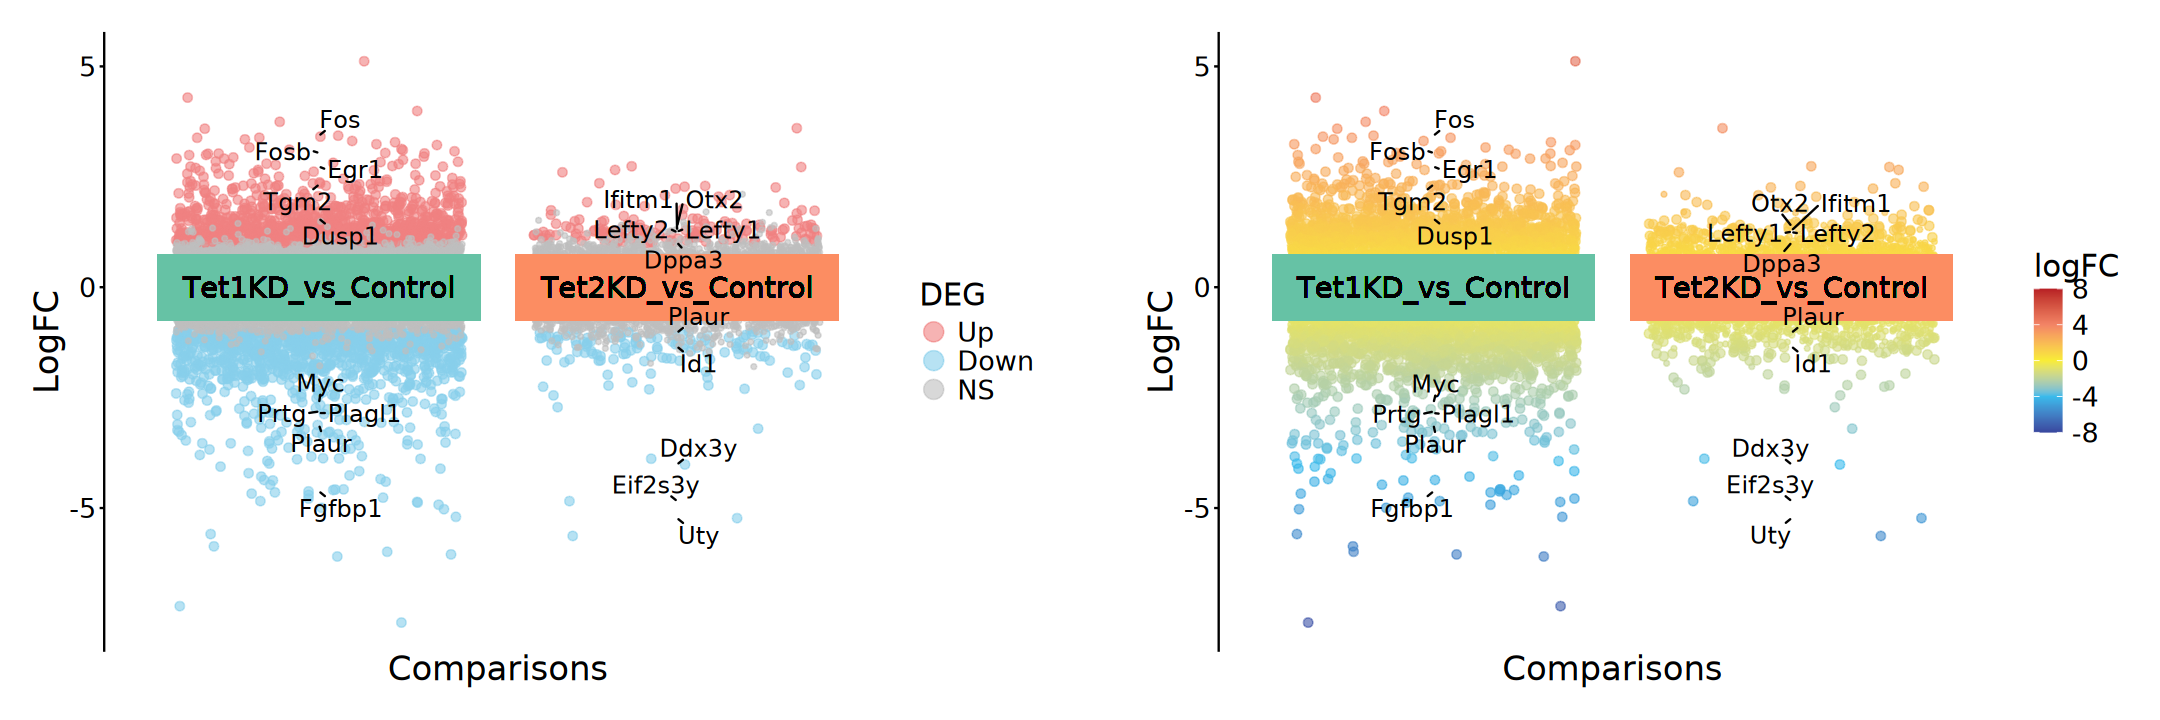

In [100]:
options(repr.plot.width = 18, repr.plot.height = 6)
p1 + plot_spacer() + p2 +
    plot_layout(nrow = 1, widths = c(1, 0.05, 1))

### Bubble Matrix Plot

In [101]:
top_genes <- deg_df |> filter(result != "NS") |> 
    group_by(contrast) |> 
    slice_min(order_by = padj, n = 5) |> 
    slice_max(order_by = abs(logFC), n = 5) |> 
    pull(gene_id) |> unique()

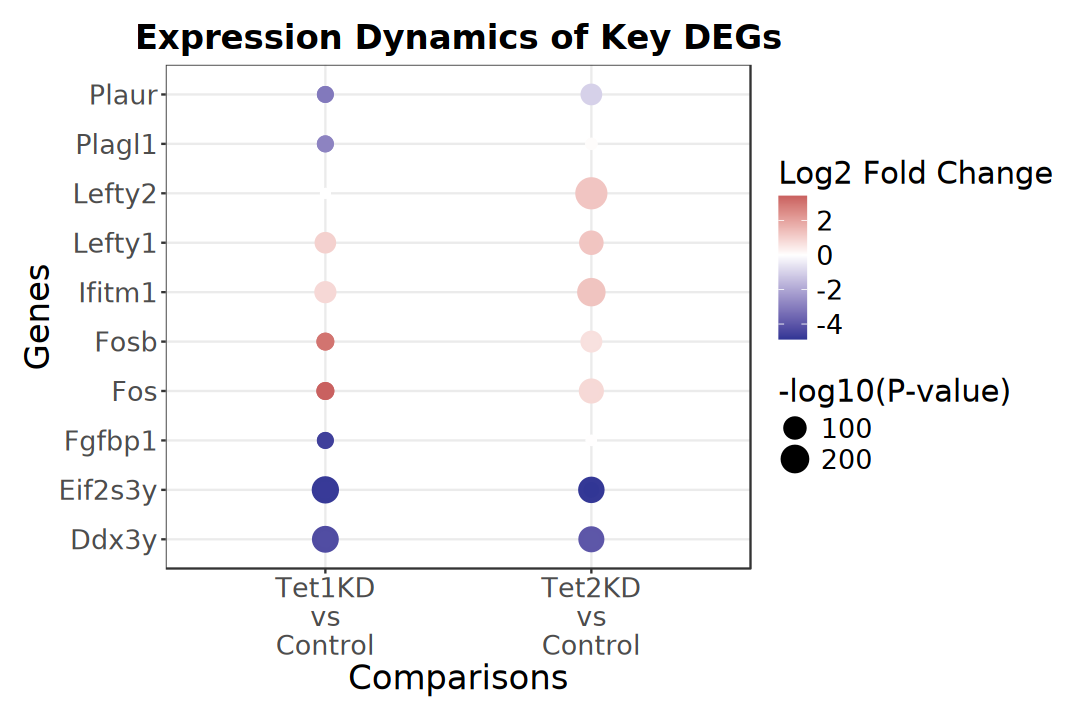

In [102]:
options(repr.plot.width = 9, repr.plot.height = 6)

all_results |> filter(gene_id %in% top_genes) |> 
    mutate(
        Group = str_replace_all(contrast, "_", "\n"),
        neg_log10P = -log10(pvalue)) |> 
    ggplot(aes(x = Group, y = symbol, size = neg_log10P, color = logFC)) +
    geom_point() +
    scale_color_gradient2(
        low = "#313695", mid = "white", high = "#a50026", 
        midpoint = 0) +
    scale_size_continuous(range = c(2, 8)) +
    labs(
        title = "Expression Dynamics of Key DEGs",
        x = "Comparisons", y = "Genes",
        color = "Log2 Fold Change", size = "-log10(P-value)") +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 20),
        axis.text = element_text(size = 16))

### Heatmap

In [103]:
heatmap_dat <- deg_df |>
    filter(result %in% c("Up", "Down")) |>
    pull(gene_id) |>
    unique() |>
    (\(idx) norm_mat[idx, ])()

In [104]:
ar <- deg_df |> 
    dplyr::select(gene_id, contrast, DEG = result) |>
    pivot_wider(names_from = contrast, values_from = DEG) |> 
    column_to_rownames("gene_id") |> 
    dplyr::select(all_of(contrast_labels))


ac <- colData(dds) |> as.data.frame() |>
    dplyr::select(Replicate, Genotype)

In [105]:
group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(dds$Genotype)),
    levels(dds$Genotype))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(dds$Replicate)),
    levels(dds$Replicate))
deg_colors <- c(Up = "LightCoral", Down = "SkyBlue", NS = "grey")

anno_colors <- setNames(
    replicate(length(contrast_labels), deg_colors, simplify = FALSE), 
    contrast_labels) |>
    append(list(Genotype = group_colors, Replicate = replicate_colors))

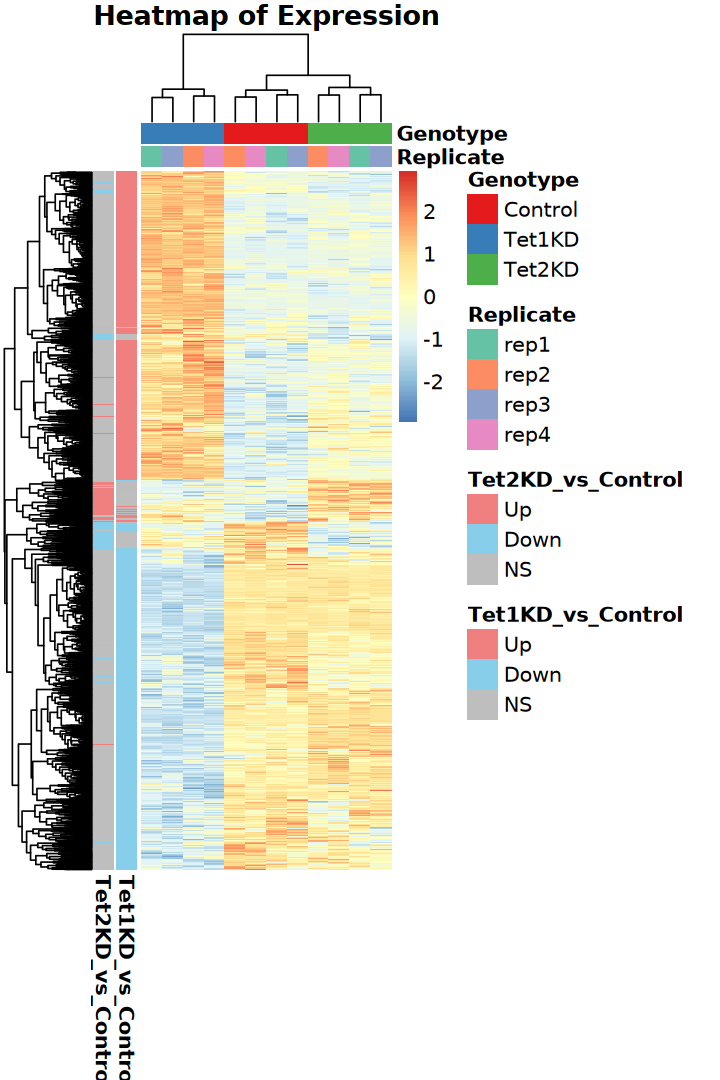

In [106]:
options(repr.plot.width = 6, repr.plot.height = 9)

pheatmap::pheatmap(
    heatmap_dat, scale = "row",
    annotation_row = ar, annotation_col = ac, 
    annotation_colors = anno_colors, 
    main = "Heatmap of Expression", fontsize = 12, 
    show_colnames = FALSE, show_rownames = FALSE)

### ComplexHeatmap

In [107]:
# suppressPackageStartupMessages(library(circlize))
suppressPackageStartupMessages(library(ComplexHeatmap))

In [108]:
heatmap_dat <- deg_df |>
    filter(result %in% c("Up", "Down")) |>
    pull(gene_id) |>
    unique() |>
    (\(idx) norm_mat[idx, ])()

In [109]:
heatmap_col <- circlize::colorRamp2(
    breaks = c(-2, 0, 2), 
    colors = rev(brewer.pal(n = 3, name = "RdYlBu")))

group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(dds$Genotype)),
    levels(dds$Genotype))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(dds$Replicate)),
    levels(dds$Replicate))

deg_colors <- c(Up = "LightCoral", Down = "SkyBlue", NS = "grey")

In [110]:
ac <- colData(dds) |> as.data.frame() |>
    dplyr::select(Genotype, Replicate)

top_anno <- HeatmapAnnotation(
    df = ac, col = list(
        Genotype = group_colors, 
        Replicate = replicate_colors))

In [111]:
ar <- deg_df |> 
    dplyr::select(gene_id, contrast, DEG = result) |>
    pivot_wider(names_from = contrast, values_from = DEG) |> 
    filter(gene_id %in% rownames(heatmap_dat)) |>
    column_to_rownames("gene_id") |> 
    dplyr::select(all_of(contrast_labels))

anno_colors <- setNames(
    replicate(length(contrast_labels), deg_colors, simplify = FALSE), 
    contrast_labels)

left_anno <- rowAnnotation(
    df = ar, col = anno_colors, show_legend = FALSE)

In [112]:
gene_labels <- deg_df |>
    dplyr::filter(!is.na(label)) |>
    dplyr::select(gene_id, label)

mark_rows <- which(rownames(heatmap_dat) %in% gene_labels$gene_id)
mark_labels <- gene_labels$label[
    match(rownames(heatmap_dat)[mark_rows], gene_labels$gene_id)]

right_anno <- rowAnnotation(
    foo = anno_mark(
        at = mark_rows,
        labels = mark_labels,
        labels_gp = gpar(fontsize = 12)))

In [113]:
lg_heatmap <- Legend(title = "Expression (z-score)",
                     col_fun = heatmap_col)

lg_group <- Legend(title = "Group", 
                   labels = levels(dds$Group))

lg_replicate <- Legend(title = "Replicate", 
                       labels = levels(dds$Replicate))

lg_deg <- Legend(labels = levels(deg_df$result), title = "DEG", 
                 legend_gp = gpar(fill = deg_colors))

combined_leg <- list(lg_heatmap, lg_group, lg_replicate) |>
    packLegend(direction = "vertical")

In [114]:
ht <- heatmap_dat |> t() |> scale() |> t() |>
    Heatmap(name = "Expression", col = heatmap_col,
            top_annotation = top_anno,
            left_annotation = left_anno, 
            right_annotation = right_anno,
            show_row_names = FALSE, 
            show_column_names = FALSE, 
            use_raster = TRUE)

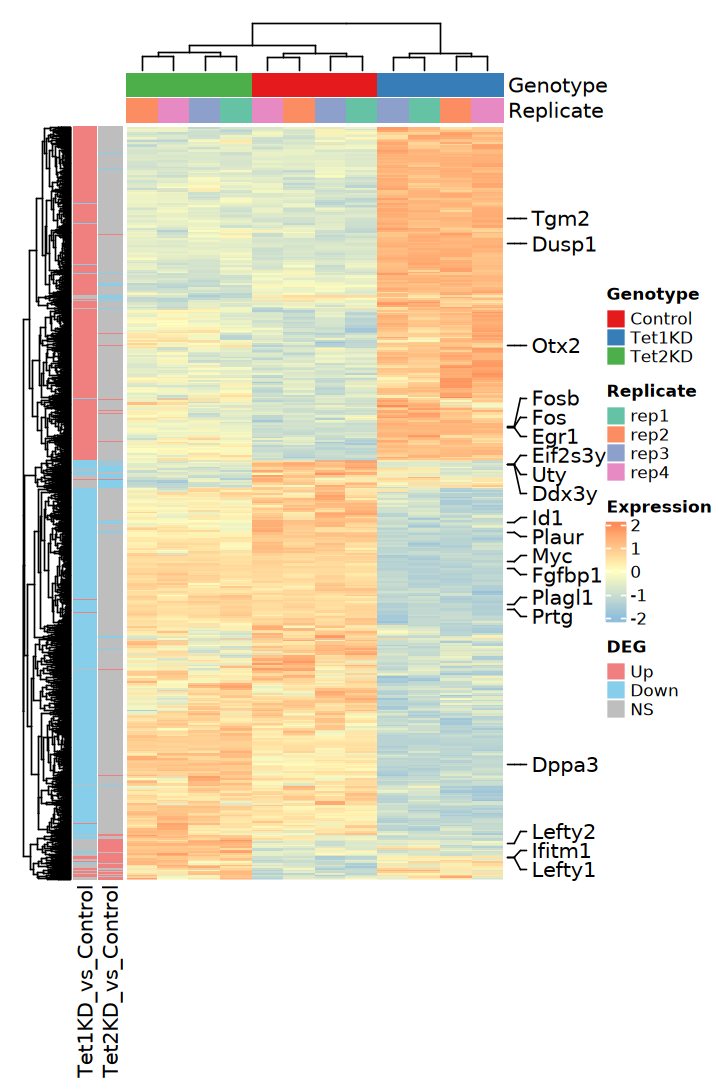

In [115]:
options(repr.plot.width = 6, repr.plot.height = 9)
draw(ht + combined_leg, merge_legend = TRUE,
     annotation_legend_list = list(lg_deg), 
     legend_title_gp = gpar(fontsize = 12, fontface = "bold"),
     legend_labels_gp = gpar(fontsize = 10), 
     padding = unit(c(5, 5, 5, 5), "mm"))

# 6. Gene Function Analysis

## 1). ORA

> Over-Representation Analysis

In [116]:
suppressPackageStartupMessages(library(org.Mm.eg.db))
suppressPackageStartupMessages(library(clusterProfiler))

In [117]:
add_ENTREZID <- function(
    res, col, orgdb, fromType = "SYMBOL", toType = "ENTREZID", 
    ignoreVersion = FALSE) {
    
    gene_ids <- res[[col]]

    if(fromType == "ENSEMBL" & ignoreVersion) {
        gene_ids <- sub("\\..*$", "", gene_ids)
    }

    gene_map <- clusterProfiler::bitr(
        gene_ids, OrgDb = orgdb, drop = FALSE, 
        fromType = fromType, toType = toType)
    
    idx <- match(gene_ids, gene_map[[fromType]])

    for (col in toType) {
        res[[col]] <- gene_map[[col]][idx]
    }
    
    return(res)
}

In [118]:
deg_df <- bind_rows(deseq2_result_list) |>
    group_by(contrast, result) |>
    arrange(padj, logFC |> abs() |> desc()) |>
    mutate(
        label = ifelse(
            type == "protein_coding" & 
                result %in% c("Up", "Down") & 
                row_number() <= 5, 
            symbol, NA_character_)) |>
    ungroup() |>
    mutate(contrast = factor(contrast, levels = contrast_labels))

table(deg_df$contrast, deg_df$result)

                   
                       Up  Down    NS
  Tet1KD_vs_Control  1020  1096 16590
  Tet2KD_vs_Control   153   138 18415

In [119]:
deg_df <- add_ENTREZID(
    deg_df, "gene_id", org.Mm.eg.db, fromType = "ENSEMBL", 
    toType = c("SYMBOL", "ENTREZID"), ignoreVersion = TRUE)

'select()' returned 1:many mapping between keys and columns

Warning message in clusterProfiler::bitr(gene_ids, OrgDb = orgdb, drop = FALSE, :
"13.9% of input gene IDs are fail to map..."


In [120]:
deg_types <- c("Up", "Down")

genes_list <- crossing(comp = contrast_labels, deg = deg_types) |>
    pmap(~ deg_df$symbol[deg_df$result == .y & deg_df$contrast == .x]) |>
    set_names(paste(
        contrast_labels, rep(deg_types, each = length(contrast_labels)), 
        sep = "_")) |>
    map(unique)

In [121]:
ego_compare <- compareCluster(
    geneCluster = genes_list, fun = enrichGO, 
    universe = unique(deg_df$SYMBOL), 
    OrgDb = org.Mm.eg.db, ont = "ALL", 
    keyType = 'SYMBOL', pAdjustMethod = "BH",
    pvalueCutoff = 0.01, qvalueCutoff = 0.05, 
    minGSSize = 10, maxGSSize = 500, readable = TRUE)

In [122]:
ego_compare |> dplyr::select(-one_of("geneID")) |> head()

,Cluster,ONTOLOGY,ID,Description,GeneRatio,BgRatio,RichFactor,FoldEnrichment,zScore,pvalue,p.adjust,qvalue,Count
,<fct>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
1,Tet1KD_vs_Control_Up,BP,GO:0048705,skeletal system morphogenesis,45/871,220/13830,0.2045455,3.247834,8.712951,1.308701e-12,6.348511e-09,5.055720e-09,45
2,Tet1KD_vs_Control_Up,BP,GO:0007389,pattern specification process,63/871,410/13830,0.1536585,2.439836,7.672688,3.063407e-11,6.950750e-08,5.535321e-08,63
3,Tet1KD_vs_Control_Up,BP,GO:0045165,cell fate commitment,44/871,235/13830,0.1872340,2.972958,7.908261,5.237838e-11,6.950750e-08,5.535321e-08,44
4,Tet1KD_vs_Control_Up,BP,GO:0060485,mesenchyme development,50/871,290/13830,0.1724138,2.737638,7.752963,5.731395e-11,6.950750e-08,5.535321e-08,50
5,Tet1KD_vs_Control_Up,BP,GO:0003002,regionalization,57/871,373/13830,0.1528150,2.426443,7.240247,3.427308e-10,2.930798e-07,2.333979e-07,57
6,Tet1KD_vs_Control_Up,BP,GO:0050727,regulation of inflammatory response,48/871,286/13830,0.1678322,2.664890,7.375878,3.624981e-10,2.930798e-07,2.333979e-07,48


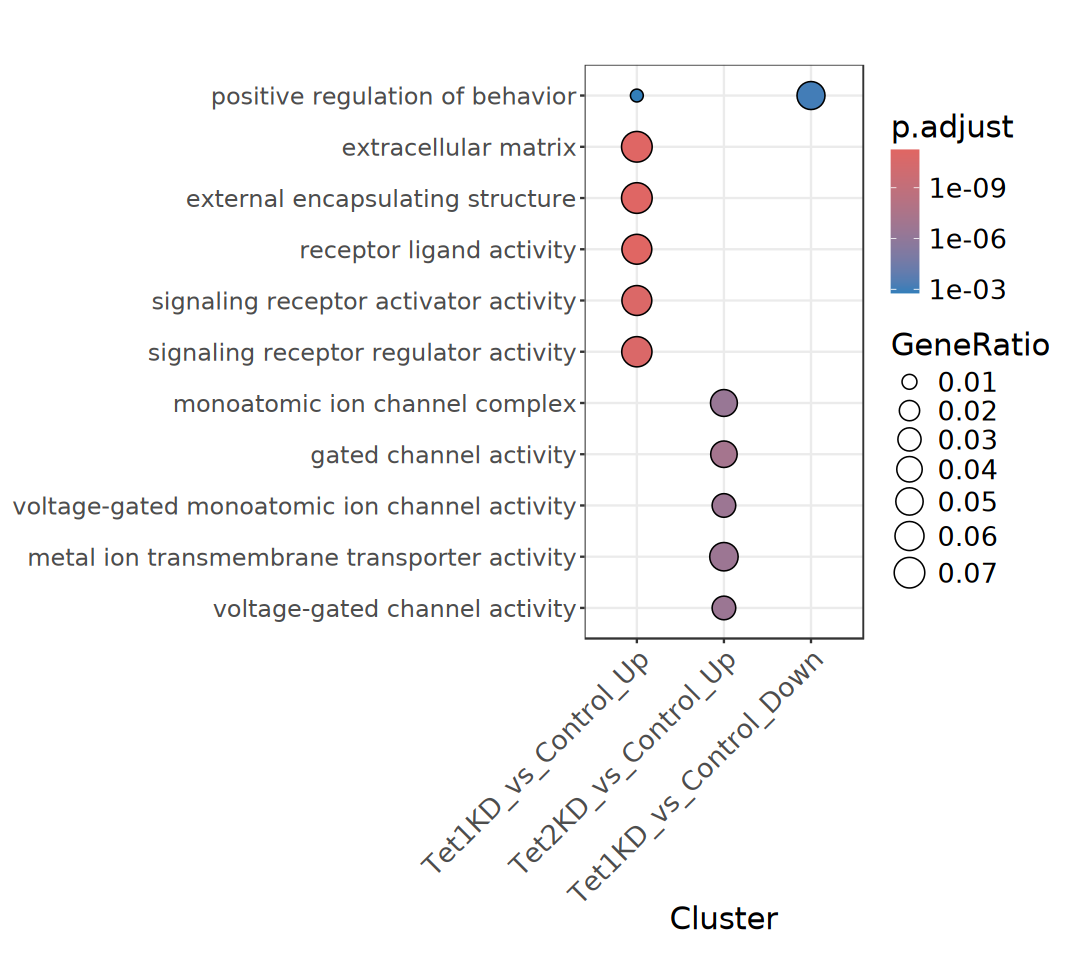

In [123]:
options(repr.plot.width = 9, repr.plot.height = 8)

dotplot(ego_compare, showCategory = 5, label_format = 50) + 
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text.x = element_text(size = 16, angle = 45, hjust = 1), 
        axis.text.y = element_text(size = 14))

In [124]:
deg_types <- c("Up", "Down")

genes_list <- crossing(comp = contrast_labels, deg = deg_types) |>
    pmap(~ deg_df$ENTREZID[deg_df$result == .y & deg_df$contrast == .x]) |>
    set_names(paste(
        contrast_labels, rep(deg_types, each = length(contrast_labels)), 
        sep = "_")) |>
    map(unique)

In [125]:
ekegg_compare <- compareCluster(
    geneCluster = genes_list, fun = enrichKEGG, 
    universe = unique(deg_df$ENTREZID), 
    organism = "mmu", pAdjustMethod = "BH",
    pvalueCutoff = 0.01, qvalueCutoff = 0.05, 
    minGSSize = 10, maxGSSize = 500)

Warning message in file(file, "rt"):
"URL 'https://raw.githubusercontent.com/YuLab-SMU/clusterProfiler/refs/heads/gh-pages/md5.txt': Timeout of 60 seconds was reached"
Warning message in file(file, "rt"):
"URL 'https://raw.githubusercontent.com/YuLab-SMU/clusterProfiler/refs/heads/gh-pages/md5.txt': Timeout of 60 seconds was reached"


In [126]:
ekegg_compare |> dplyr::select(-one_of("geneID")) |> head()

,Cluster,category,subcategory,ID,Description,GeneRatio,BgRatio,RichFactor,FoldEnrichment,zScore,pvalue,p.adjust,qvalue,Count
,<fct>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
1,Tet1KD_vs_Control_Up,Environmental Information Processing,Signaling molecules and interaction,mmu04061,Viral protein interaction with cytokine and cytokine receptor,15/418,32/6327,0.4687500,7.095170,9.193031,3.117703e-10,7.110564e-08,6.493439e-08,15
2,Tet1KD_vs_Control_Up,Environmental Information Processing,Signaling molecules and interaction,mmu04060,Cytokine-cytokine receptor interaction,31/418,135/6327,0.2296296,3.475758,7.733129,4.708983e-10,7.110564e-08,6.493439e-08,31
3,Tet1KD_vs_Control_Up,Human Diseases,Immune disease,mmu05323,Rheumatoid arthritis,15/418,56/6327,0.2678571,4.054383,6.105832,2.047850e-06,2.061502e-04,1.882585e-04,15
4,Tet1KD_vs_Control_Up,Cellular Processes,Cell motility,mmu04820,Cytoskeleton in muscle cells,30/418,191/6327,0.1570681,2.377439,5.140936,6.396458e-06,4.829326e-04,4.410190e-04,30
5,Tet2KD_vs_Control_Up,Environmental Information Processing,Signaling molecules and interaction,mmu04080,Neuroactive ligand-receptor interaction,25/350,147/6327,0.1700680,3.074344,6.157469,3.617815e-07,5.963244e-05,5.371748e-05,25
6,Tet2KD_vs_Control_Up,Environmental Information Processing,Signaling molecules and interaction,mmu04082,Neuroactive ligand signaling,20/350,100/6327,0.2000000,3.615429,6.379115,3.822592e-07,5.963244e-05,5.371748e-05,20


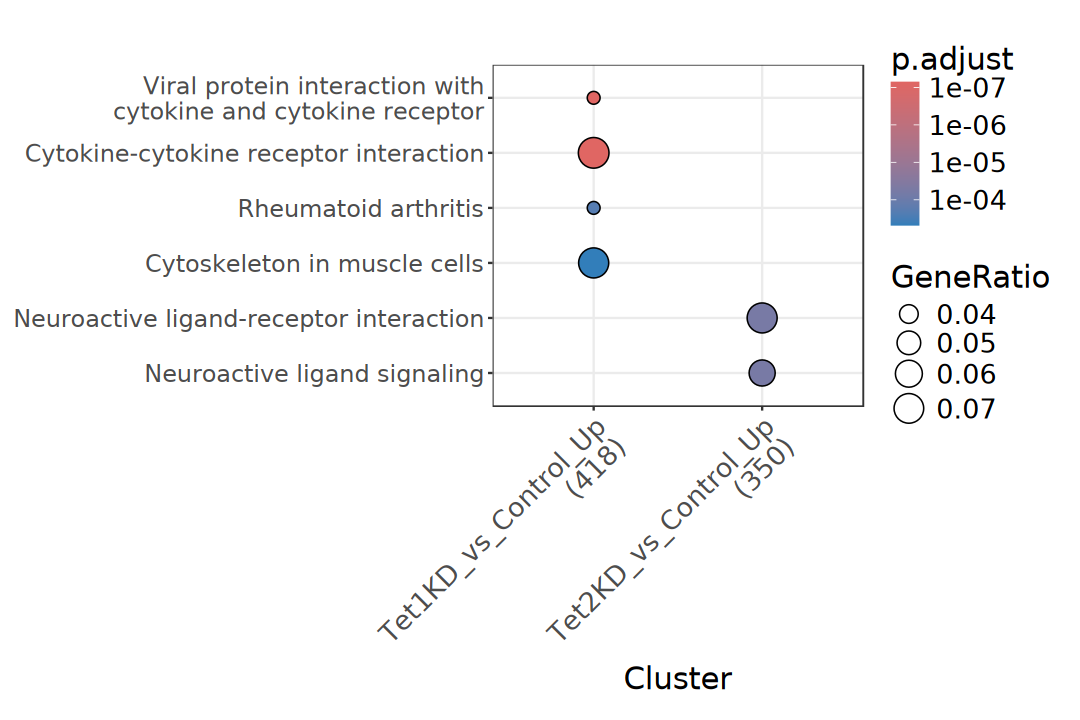

In [127]:
options(repr.plot.width = 9, repr.plot.height = 6)

dotplot(ekegg_compare, showCategory = 5, label_format = 40) + 
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text.x = element_text(size = 16, angle = 45, hjust = 1), 
        axis.text.y = element_text(size = 14))

## 2). GSEA

> Gene Set Enrichment Analysis

# Reference

> 1. Law CW, Alhamdoosh M, Su S, Dong X, Tian L, Smyth GK, Ritchie ME (2018). “RNA-seq analysis is easy as 1-2-3 with limma, Glimma and edgeR.” F1000Research, 5, 1408. https://f1000research.com/articles/5-1408/v3. [RNA-seq analysis is easy as 1-2-3 with limma, Glimma and edgeR](https://www.bioconductor.org/packages/release/workflows/html/RNAseq123.html)
> 2. Law CW, Zeglinski K, Dong X, Alhamdoosh M, Smyth GK, Ritchie ME (2020). “A guide to creating design matrices for gene expression experiments.” F1000Research, 9, 1444. https://f1000research.com/articles/9-1444. [A guide to creating design matrices for gene expression experiments](https://www.bioconductor.org/packages/release/workflows/vignettes/RNAseq123/inst/doc/designmatrices.html)
> 2. Love MI, Anders S, Kim V, Huber W (2016). “RNA-Seq workflow: gene-level exploratory analysis and differential expression.” F1000Research. doi:10.12688/f1000research.7035.2. [RNA-seq workflow: gene-level exploratory analysis and differential expression](https://www.bioconductor.org/packages/release/workflows/html/rnaseqGene.html)
> 3. Chen Y, Lun ATL, Smyth GK (2016). “From reads to genes to pathways: differential expression analysis of RNA-Seq experiments using Rsubread and the edgeR quasi-likelihood pipeline.” F1000Research, 5, 1438. http://f1000research.com/articles/5-1438. [Gene-level RNA-seq differential expression and pathway analysis using Rsubread and the edgeR quasi-likelihood pipeline](https://www.bioconductor.org/packages/release/workflows/html/RnaSeqGeneEdgeRQL.html)